# Laboratorio: OpenAI Decisions API vs YOLO11n-cls

## Inspección visual de defectos en placas PCB (dataset VisA, categoría `pcb1`)

**Pregunta de investigación.** En una tarea de control de calidad visual (clasificación binaria por imagen: `normal` vs `anomaly`, con `anomaly` como clase positiva), ¿cómo se compara una **API multimodal de propósito general sin ajuste específico** (OpenAI Decisions API, modelo `gpt-6-luna`) frente a un **clasificador convolucional pequeño entrenado específicamente** (YOLO11n-cls), sobre las mismas 60 imágenes de test?

**Resumen de resultados (test, 60 imágenes: 30 normal / 30 anomalía).**

| Método | N | Umbral | Accuracy | Precision | Recall | F1 | TP/TN/FP/FN |
|---|---:|---:|---:|---:|---:|---:|---|
| YOLO11n-cls | 60 | 0,50 | **93,33%** | 90,62% | **96,67%** | 0,9355 | 29/27/3/1 |
| Decisions API V1 | 60 | 0,20 | 81,67% | 85,19% | 76,67% | 0,8070 | 23/26/4/7 |

Diferencia observada: **+11,67 puntos de accuracy** y **+20 puntos de recall** a favor de YOLO. En 9 discordancias de acierto, YOLO acierta 8 y la API 1 (McNemar exacto bilateral p = 0,0390625). Es un resultado de laboratorio, sobre una muestra local pequeña, balanceada y ya inspeccionada; **no autoriza una afirmación de superioridad universal ni de aptitud para producción**. Todo el detalle y las salvedades están en este notebook y en `reports/comparacion-20261013.md`.

---

**Contenido**

1. Marco del problema y arquitectura del laboratorio
2. Pipeline de scripts
3. Dataset VisA `pcb1` y particiones reproducibles
4. Exploración V1 vs V2 (prompts)
5. Benchmark de Decisions API con checkpoints
6. YOLO11n-cls: dataset, entrenamiento y pesos
7. Congelamiento del umbral en validación
8. Comparación pareada en test
9. Diagnóstico de errores con máscaras
10. Latencia y entorno
11. Integridad y trazabilidad
12. Limitaciones
13. Próximos pasos
14. Reproducción
15. Conclusiones

## Cómo usar este notebook

- Este notebook es **de lectura: reproduce y explica la evidencia ya existente**. NO llama a la API de OpenAI, NO reentrena YOLO y NO escribe sobre resultados previos.
- Lee CSV/JSON/PNG que ya están en el repositorio (`results/`, `data/`). Por eso puede ejecutarse completo sin coste y sin GPU.
- Las únicas celdas que requerirían GPU son las de inferencia YOLO; aquí **no se re-ejecuta inferencia**: se leen `yolo_predictions_validation.csv` y `yolo_predictions_test.csv`, producidos por `scripts/offline_audit_compare.py`.
- Los umbrales (API 0,20 / YOLO 0,50) están **congelados**; el notebook solo verifica que la política declarada los reproduce.
- Los valores históricos de la API (exploración V1/V2) no conservan respuesta cruda recuperable para todas las llamadas; se marcan como reconstruidos.

---
## 1. Marco del problema y arquitectura del laboratorio

El problema se modela como **clasificación binaria por imagen** (no detección ni segmentación):

- Clase positiva: `anomaly` (defecto visible). Clase negativa: `normal`.
- YOLO11n-cls es un **clasificador**: no produce cajas ni máscaras.
- Decisions API responde a un **predicado visual** llamado `visible_defect` y devuelve una probabilidad; no localiza el defecto ni devuelve una explicación.
- Ninguno de los dos métodos certifica el funcionamiento **eléctrico** de la placa; ambos hacen solo inspección visual.
- Regla de decisión común a los dos: `anomaly` si `probability >= threshold`.

```mermaid
flowchart LR
  A[VisA pcb1 + anotaciones] --> B[Manifiestos reproducibles]
  B --> E[Exploracion V1 y V2]
  B --> T[Train: 240 imagenes]
  T --> Y[YOLO11n-cls entrenado]
  B --> V[Validation: 40 imagenes]
  V --> C[Seleccion de umbral por metodo]
  Y --> C
  C --> F[Umbrales congelados + hashes]
  B --> S[Test: 60 imagenes]
  F --> P[Comparacion pareada]
  S --> P
  P --> R[Metricas + diagnostico con mascaras]
```

Componentes de código relevantes:

- `src/decisions/client.py`: convierte la imagen a data URL y llama a `client.decisions.create(model='gpt-6-luna', questions=[predicate visible_defect])`. Define `PROMPT_V1` y `PROMPT_V2`.
- `scripts/run_benchmark_v4.py`: benchmark con **checkpoints y resume** (no repite llamadas exitosas).
- `scripts/train_yolo.py` y `scripts/evaluate_yolo.py`: entrenamiento e inferencia YOLO.
- `scripts/offline_audit_compare.py`: auditoría + congelamiento de umbral + test pareado **sin tocar la API**.
- `scripts/document_verified_state.py`: genera estadísticas de máscaras, inventario de errores y la figura diagnóstica.

### 1.1 Pipeline de scripts del laboratorio

Cada script cumple una etapa concreta. Los que **escriben o gastan dinero** (benchmark API, entrenamiento, manifiestos) no deben re-ejecutarse solo para leer resultados.

In [1]:
import pandas as pd

stages = [
    ('scripts/download_visa.py', 'Descarga VisA_20220922.tar desde AWS Open Data', 'data/raw/'),
    ('scripts/prepare_pcb1.py', 'Extrae una PCB normal y una anomala de pcb1', 'data/samples/'),
    ('scripts/inspect_one.py', 'Primera decision individual con Decisions API (gasta)', 'stdout'),
    ('scripts/prepare_benchmark.py', 'Construye benchmark_pcb1.csv (semillas 42/43)', 'data/benchmark_pcb1.csv'),
    ('scripts/run_benchmark.py', 'Exploracion V1/V2 con 20 imagenes (gasta, sin cache seguro)', 'results/predictions*.csv'),
    ('scripts/analyze_thresholds.py', 'Barrido de umbrales sobre exploracion', 'results/threshold_analysis*.csv'),
    ('scripts/compare_prompts.py', 'Compara V1 vs V2 lado a lado', 'results/prompt_comparison.csv'),
    ('scripts/calculate_metrics.py', 'Metricas sklearn sobre predictions_v2.csv', 'stdout'),
    ('scripts/prepare_dataset_splits.py', 'Particiones con random.Random(42), excluye exploracion', 'data/pcb1_splits.csv'),
    ('scripts/prepare_yolo_dataset.py', 'Copia imagenes a train/val/test por clase', 'data/yolo_pcb1/'),
    ('scripts/train_yolo.py', 'Entrena YOLO11n-cls (50 epocas max, imgsz 320)', 'results/yolo/pcb1_cls_v1/'),
    ('scripts/evaluate_yolo.py', 'Inferencia YOLO val/test con umbral', 'results/yolo/pcb1_cls_v1/*'),
    ('scripts/run_benchmark_v4.py', 'Benchmark API con checkpoints/resume (gasta)', 'results/runs/v1_*/'),
    ('scripts/validate_and_freeze.py', 'Congela umbral API en validacion (FPR max 10%)', 'results/selected_threshold.json'),
    ('scripts/evaluate_final_test.py', 'Metricas finales del test API', 'results/final_test_metrics.json'),
    ('scripts/export_false_negatives.py', 'Exporta FN de exploracion como imagenes', 'results/false_negatives/'),
    ('scripts/offline_audit_compare.py', 'Auditoria + freeze + test pareado SIN API', 'results/audit_20261013/'),
    ('scripts/document_verified_state.py', 'Mascaras, errores y figura diagnostica', 'results/audit_20261013/'),
]

display(pd.DataFrame(stages, columns=['script', 'que hace', 'salida']))

,script,que hace,salida
0,scripts/download_visa.py,Descarga VisA_20220922.tar desde AWS Open Data,data/raw/
1,scripts/prepare_pcb1.py,Extrae una PCB normal y una anomala de pcb1,data/samples/
2,scripts/inspect_one.py,Primera decision individual con Decisions API ...,stdout
3,scripts/prepare_benchmark.py,Construye benchmark_pcb1.csv (semillas 42/43),data/benchmark_pcb1.csv
4,scripts/run_benchmark.py,"Exploracion V1/V2 con 20 imagenes (gasta, sin ...",results/predictions*.csv
5,scripts/analyze_thresholds.py,Barrido de umbrales sobre exploracion,results/threshold_analysis*.csv
6,scripts/compare_prompts.py,Compara V1 vs V2 lado a lado,results/prompt_comparison.csv
7,scripts/calculate_metrics.py,Metricas sklearn sobre predictions_v2.csv,stdout
8,scripts/prepare_dataset_splits.py,"Particiones con random.Random(42), excluye exp...",data/pcb1_splits.csv
9,scripts/prepare_yolo_dataset.py,Copia imagenes a train/val/test por clase,data/yolo_pcb1/


---
## 2. Entorno de análisis y utilidades

Se localiza la raíz del repositorio subiendo por el árbol de directorios hasta encontrar `data/pcb1_splits.csv`, de modo que el notebook funcione sin depender del directorio de trabajo.

In [2]:
from pathlib import Path
import ast
import hashlib
import json
import math
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def find_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for cand in [start, *start.parents]:
        if (cand / 'data' / 'pcb1_splits.csv').is_file():
            return cand
    raise FileNotFoundError('No se encontro la raiz del proyecto')


ROOT = find_root()
AUDIT = ROOT / 'results' / 'audit_20261013'
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 50)


def read_csv(rel):
    return pd.read_csv(ROOT / rel)


def load_json(rel):
    return json.loads((ROOT / rel).read_text(encoding='utf-8'))


def sha256(rel):
    return hashlib.sha256((ROOT / rel).read_bytes()).hexdigest()


def wilson(k, n, z=1.959963984540054):
    if n == 0:
        return (float('nan'), float('nan'))
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (c - h, c + h)


def metrics(y_true, y_prob, threshold):
    y_true = np.asarray(y_true).astype(bool)
    y_pred = np.asarray(y_prob) >= threshold
    tp = int(np.sum(y_true & y_pred))
    fn = int(np.sum(y_true & ~y_pred))
    fp = int(np.sum(~y_true & y_pred))
    tn = int(np.sum(~y_true & ~y_pred))
    n = len(y_true)
    return dict(samples=n, threshold=threshold, tp=tp, tn=tn, fp=fp, fn=fn,
                accuracy=(tp + tn) / n,
                precision=tp / (tp + fp) if (tp + fp) else 0.0,
                recall=tp / (tp + fn) if (tp + fn) else 0.0,
                f1=2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0.0,
                fpr=fp / (fp + tn) if (fp + tn) else 0.0,
                fnr=fn / (fn + tp) if (fn + tp) else 0.0,
                accuracy_ci95=wilson(tp + tn, n),
                recall_ci95=wilson(tp, tp + fn),
                fpr_ci95=wilson(fp, fp + tn))


def pct(x):
    return '%.2f%%' % (100 * x)


def ci_str(interval):
    return '%.2f%% - %.2f%%' % (100 * interval[0], 100 * interval[1])


def abcd(m):
    return '%d/%d/%d/%d' % (m['tp'], m['tn'], m['fp'], m['fn'])


def metrics_row(name, m):
    return {'metodo': name, 'N': m['samples'], 't': m['threshold'],
            'accuracy': pct(m['accuracy']), 'precision': pct(m['precision']),
            'recall': pct(m['recall']), 'F1': '%.4f' % m['f1'],
            'FPR': pct(m['fpr']), 'TP/TN/FP/FN': abcd(m)}


print('ROOT  :', ROOT)
print('AUDIT :', AUDIT.as_posix(), '| existe:', AUDIT.is_dir())
print('numpy :', np.__version__, '| pandas:', pd.__version__)

ROOT  : d:\Proyectos\IA\Lab\DecisionAPI
AUDIT : d:/Proyectos/IA/Lab/DecisionAPI/results/audit_20261013 | existe: True
numpy : 2.4.6 | pandas: 3.0.6


In [3]:
# Inventario minimo de evidencia que este notebook necesita
required = [
    'data/benchmark_pcb1.csv',
    'data/pcb1_splits.csv',
    'results/predictions.csv',
    'results/predictions_v2.csv',
    'results/prompt_comparison.csv',
    'results/threshold_analysis.csv',
    'results/threshold_analysis_v2.csv',
    'results/selected_threshold.json',
    'results/final_test_metrics.json',
    'results/runs/v1_validation/predictions.csv',
    'results/runs/v1_test/predictions.csv',
    'results/yolo/pcb1_cls_v1/experiment.json',
    'results/yolo/pcb1_cls_v1/results.csv',
    'results/yolo/pcb1_cls_v1/args.yaml',
    'results/yolo/pcb1_cls_v1/predictions_val.csv',
    'results/yolo/pcb1_cls_v1/weights/best.pt',
    'results/audit_20261013/audit.json',
    'results/audit_20261013/comparison_test.json',
    'results/audit_20261013/yolo_threshold_frozen.json',
    'results/audit_20261013/yolo_threshold_grid_validation.json',
    'results/audit_20261013/yolo_predictions_validation.csv',
    'results/audit_20261013/yolo_predictions_test.csv',
    'results/audit_20261013/paired_test.csv',
    'results/audit_20261013/error_inventory.csv',
    'results/audit_20261013/mask_statistics.csv',
    'results/audit_20261013/mask_summary.json',
    'results/audit_20261013/verification.json',
]

inv = pd.DataFrame({
    'artifact': required,
    'existe': [(ROOT / p).exists() for p in required],
    'KB': [round((ROOT / p).stat().st_size / 1024, 1) if (ROOT / p).exists() else None for p in required],
})
assert inv['existe'].all(), inv.loc[~inv['existe']]
display(inv)

,artifact,existe,KB
0,data/benchmark_pcb1.csv,True,1.1
1,data/pcb1_splits.csv,True,20.5
2,results/predictions.csv,True,1.6
3,results/predictions_v2.csv,True,1.7
4,results/prompt_comparison.csv,True,2.8
5,results/threshold_analysis.csv,True,1.0
6,results/threshold_analysis_v2.csv,True,1.1
7,results/selected_threshold.json,True,0.3
8,results/final_test_metrics.json,True,0.4
9,results/runs/v1_validation/predictions.csv,True,5.0


---
## 3. Dataset VisA `pcb1` y particiones reproducibles

- **VisA (Visual Anomaly)**, Amazon Science / AWS Open Data; licencia **CC BY 4.0**.
- 10.821 imágenes, 12 categorías. La categoría `pcb1` tiene **1.004 normales y 100 anómalas**.
- Cada imagen anómala tiene una **máscara** de defecto; las normales no tienen máscara.
- La partición es **local**: no es el split oficial de VisA.

| Conjunto | Normal | Anomaly | Total | Uso |
|---|---:|---:|---:|---|
| Exploración | 10 | 10 | 20 | Comparar V1/V2 y estudiar errores |
| Train | 200 | 40 | 240 | Ajustar YOLO |
| Validation | 20 | 20 | 40 | Seleccionar checkpoint y umbral |
| Test | 30 | 30 | 60 | Comparación final, sin ajuste posterior |
| No asignado | 744 | 0 | 744 | Reserva normal |

Nota metodológica: `train` está desbalanceado 5:1, mientras que `validation` y `test` están balanceados 1:1. Eso hace que precision y accuracy dependan de la prevalencia elegida.

In [4]:
raw = ROOT / 'data/raw/pcb1/Data/Images'
manifest = read_csv('data/pcb1_splits.csv')
exploration = read_csv('data/benchmark_pcb1.csv')

print('Normal crudo :', len(list((raw / 'Normal').glob('*.JPG'))))
print('Anomaly crudo:', len(list((raw / 'Anomaly').glob('*.JPG'))))
print('Manifest     :', len(manifest), 'filas | Exploracion:', len(exploration), 'filas')

counts = (manifest.groupby(['split', 'ground_truth']).size()
          .unstack(fill_value=0)
          .reindex(['train', 'validation', 'test']))
counts['total'] = counts.sum(axis=1)
display(counts)
display(manifest.head(4))

Normal crudo : 1004
Anomaly crudo: 100
Manifest     : 340 filas | Exploracion: 20 filas


ground_truth,anomaly,normal,total
split,,,
train,40,200,240
validation,20,20,40
test,30,30,60


,image,category,ground_truth,split
0,data/raw/pcb1/Data/Images/Normal/0411.JPG,pcb1,normal,train
1,data/raw/pcb1/Data/Images/Normal/0089.JPG,pcb1,normal,train
2,data/raw/pcb1/Data/Images/Normal/0234.JPG,pcb1,normal,train
3,data/raw/pcb1/Data/Images/Normal/0946.JPG,pcb1,normal,train


In [5]:
# Reproduccion READ-ONLY del manifiesto con random.Random(42)
# Misma logica que scripts/prepare_dataset_splits.py y la auditoria.
def reproduce_manifest():
    rng = random.Random(42)
    excluded = {(ROOT / p).resolve() for p in exploration['image']}
    rows = []
    for label, folder in [('normal', 'Normal'), ('anomaly', 'Anomaly')]:
        files = [p for p in sorted((raw / folder).iterdir())
                 if p.suffix.lower() in {'.jpg', '.jpeg', '.png', '.webp'} and p.resolve() not in excluded]
        rng.shuffle(files)
        offset = 0
        for split, n in [('validation', 20), ('test', 30), ('train', 200 if label == 'normal' else 40)]:
            for p in files[offset:offset + n]:
                rows.append({'image': p.relative_to(ROOT).as_posix(), 'category': 'pcb1',
                             'ground_truth': label, 'split': split})
            offset += n
    rng.shuffle(rows)
    return pd.DataFrame(rows, columns=['image', 'category', 'ground_truth', 'split'])


reproduced = reproduce_manifest()
identical = reproduced.reset_index(drop=True).equals(manifest.reset_index(drop=True))
leak = set(exploration['image']) & set(manifest['image'])

print('Reproduce exactamente pcb1_splits.csv  :', identical)
print('Imagenes de exploracion dentro de splits:', len(leak))
print('Filas duplicadas en manifest            :', int(manifest['image'].duplicated().sum()))

img_to_split = dict(zip(manifest['image'], manifest['split']))
hash_to_splits = {}
for img in manifest['image']:
    hash_to_splits.setdefault(sha256(img), set()).add(img_to_split[img])
cross = [h for h, s in hash_to_splits.items() if len(s) > 1]
print('Duplicados byte a byte entre splits     :', len(cross))
print('Copias YOLO verificadas por la auditoria: 340 (ver audit.json)')

Reproduce exactamente pcb1_splits.csv  : True
Imagenes de exploracion dentro de splits: 0
Filas duplicadas en manifest            : 0
Duplicados byte a byte entre splits     : 0
Copias YOLO verificadas por la auditoria: 340 (ver audit.json)


### 3.1 Salvedad de exposición previa (smoke test)

El Sprint 1 preparó dos imágenes sueltas: `Normal/0000.JPG` (no asignada) y `Anomaly/000.JPG`. El generador de splits **no las excluyó**, por lo que `000.JPG` quedó en `validation`. Sus llamadas originales a la API no se recuperaron. El **test no contiene** esas imágenes y no comparte datos con `train`. La validación queda, por tanto, con una pequeña exposición previa que se documenta sin redefinir las particiones.

In [6]:
audit = load_json('results/audit_20261013/audit.json')
display(pd.DataFrame(audit['initial_smoke_overlap']))
print('Nota:', audit['caveat'])

,ground_truth,source,sample,split
0,normal,data/raw/pcb1/Data/Images/Normal/0000.JPG,data/samples/pcb1_normal.JPG,NaN
1,anomaly,data/raw/pcb1/Data/Images/Anomaly/000.JPG,data/samples/pcb1_anomaly.JPG,validation


Nota: Initial smoke samples were not excluded by the split generator. Test independence is assessed separately from this validation exposure.


---
## 4. Exploración V1 vs V2 (los prompts)

Contexto común enviado en ambas versiones:

> Inspect this printed circuit board (PCB) as part of an industrial visual quality-control process.

Modelo `gpt-6-luna`, pregunta tipo `predicate` con nombre `visible_defect`.

- **V1**: pregunta genérica sobre anomalía visible, con instrucción de ignorar iluminación, sombras, reflejos y perspectiva.
- **V2**: describe un módulo **HC-SR04** y su configuración esperada (4 pines Vcc/Trig/Echo/Gnd, pines rectos, sin soldaduras anómalas, sin transductores deformados, etc.).

Aviso de trazabilidad: los CSV de exploración **no registran la versión del prompt** ni conservan las respuestas crudas; la atribución V1/V2 se basa en el nombre del archivo y el código conservado. Los checkpoints v4 sí registran `prompt_version=v1`.

In [7]:
# Extraccion de los prompts desde el codigo fuente con AST (sin instanciar el cliente de OpenAI)
tree = ast.parse((ROOT / 'src/decisions/client.py').read_text(encoding='utf-8'))
prompts = {}
for node in tree.body:
    if isinstance(node, ast.Assign) and isinstance(node.targets[0], ast.Name) and node.targets[0].id.startswith('PROMPT_'):
        prompts[node.targets[0].id] = ast.literal_eval(node.value)

for name in ['PROMPT_V1', 'PROMPT_V2']:
    print('=' * 78)
    print(name, '(%d caracteres)' % len(prompts[name]))
    print('-' * 78)
    print(prompts[name].strip())
print('=' * 78)
print('Prompt snapshot sha256:', sha256('results/audit_20261013/prompt_snapshot.json'))

PROMPT_V1 (346 caracteres)
------------------------------------------------------------------------------
Does this PCB show a visible manufacturing anomaly or defect? Look for observable abnormalities such as missing or misplaced components, surface damage, scratches, cracks, unusual spots, or other visible structural inconsistencies. Ignore ordinary lighting variation, shadows, reflections, perspective differences, and normal component variation.
PROMPT_V2 (1089 caracteres)
------------------------------------------------------------------------------
Determine whether this HC-SR04 ultrasonic sensor module
        contains any visible manufacturing anomaly or defect.

        Expected configuration:
        - Four connector pins labeled Vcc, Trig, Echo and Gnd.
        - All four pins must be physically present.
        - Pins should be straight and properly aligned.
        - No visibly broken, bent or missing pins.
        - No abnormal solder joints or damaged PCB traces.
        

In [8]:
# Metricas de exploracion reconstruidas (20 imagenes, umbral 0.5)
hist = load_json('results/audit_20261013/historical_metrics_recomputed.json')
display(pd.DataFrame([
    metrics_row('API exploration V1', hist['API_exploration_v1']),
    metrics_row('API exploration V2', hist['API_exploration_v2']),
]))

cmp = read_csv('results/prompt_comparison.csv')
print('Cambios V1 -> V2 por imagen:', cmp['change'].value_counts().to_dict())
print('V1 correctas:', int(cmp['v1_correct'].sum()), '| V2 correctas:', int(cmp['v2_correct'].sum()))
display(cmp[['image', 'ground_truth', 'probability_v1', 'probability_v2', 'change']].head(12))

,metodo,N,t,accuracy,precision,recall,F1,FPR,TP/TN/FP/FN
0,API exploration V1,20,0.5,80.00%,100.00%,60.00%,0.7500,0.00%,6/10/0/4
1,API exploration V2,20,0.5,55.00%,53.85%,70.00%,0.6087,60.00%,7/4/6/3


Cambios V1 -> V2 por imagen: {'UNCHANGED': 9, 'WORSENED': 8, 'IMPROVED': 3}
V1 correctas: 16 | V2 correctas: 11


,image,ground_truth,probability_v1,probability_v2,change
0,data/raw/pcb1/Data/Images/Anomaly/058.JPG,anomaly,0.11,0.27,UNCHANGED
1,data/raw/pcb1/Data/Images/Normal/0250.JPG,normal,0.09,0.63,WORSENED
2,data/raw/pcb1/Data/Images/Anomaly/018.JPG,anomaly,0.80,0.89,UNCHANGED
3,data/raw/pcb1/Data/Images/Normal/0281.JPG,normal,0.07,0.43,UNCHANGED
4,data/raw/pcb1/Data/Images/Normal/0104.JPG,normal,0.07,0.43,UNCHANGED
5,data/raw/pcb1/Data/Images/Anomaly/097.JPG,anomaly,0.18,0.60,IMPROVED
6,data/raw/pcb1/Data/Images/Anomaly/059.JPG,anomaly,0.61,0.41,WORSENED
7,data/raw/pcb1/Data/Images/Anomaly/012.JPG,anomaly,0.18,0.90,IMPROVED
8,data/raw/pcb1/Data/Images/Normal/0228.JPG,normal,0.06,0.63,WORSENED
9,data/raw/pcb1/Data/Images/Anomaly/089.JPG,anomaly,0.91,0.94,UNCHANGED


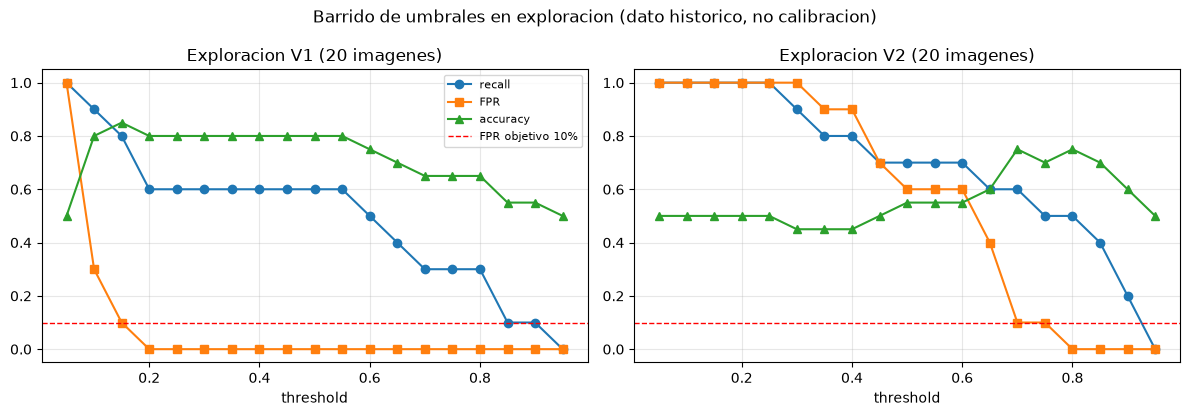

V1 a t=0.15: [{'threshold': 0.15, 'accuracy': 0.85, 'precision': 0.8888888888888888, 'recall': 0.8, 'f1': 0.8421052631578947, 'fpr': 0.1, 'fnr': 0.2, 'tp': 8, 'tn': 9, 'fp': 1, 'fn': 2}]
V2 a t=0.50: [{'threshold': 0.5, 'accuracy': 0.55, 'precision': 0.5384615384615384, 'recall': 0.7, 'f1': 0.6086956521739131, 'fpr': 0.6, 'fnr': 0.3, 'tp': 7, 'tn': 4, 'fp': 6, 'fn': 3}]


In [9]:
# Barrido de umbrales sobre la exploracion (20 imagenes). No es calibracion independiente.
t1 = read_csv('results/threshold_analysis.csv')
t2 = read_csv('results/threshold_analysis_v2.csv')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, df, title in [(axes[0], t1, 'Exploracion V1 (20 imagenes)'), (axes[1], t2, 'Exploracion V2 (20 imagenes)')]:
    ax.plot(df['threshold'], df['recall'], marker='o', label='recall')
    ax.plot(df['threshold'], df['fpr'], marker='s', label='FPR')
    ax.plot(df['threshold'], df['accuracy'], marker='^', label='accuracy')
    ax.axhline(0.10, ls='--', c='red', lw=1, label='FPR objetivo 10%')
    ax.set_title(title)
    ax.set_xlabel('threshold')
    ax.set_ylim(-0.05, 1.05)
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
fig.suptitle('Barrido de umbrales en exploracion (dato historico, no calibracion)')
plt.tight_layout()
plt.show()

print('V1 a t=0.15:', t1.loc[t1['threshold'] == 0.15].to_dict('records'))
print('V2 a t=0.50:', t2.loc[t2['threshold'] == 0.50].to_dict('records'))

---
## 5. Benchmark de Decisions API con checkpoints

`scripts/run_benchmark_v4.py` guarda un **checkpoint JSON por imagen** (clave SHA-256 de la ruta, truncada a 16 caracteres) con la respuesta cruda, la probabilidad, la latencia, el estado y el modelo. Los éxitos se reutilizan; los errores se reintentan. Este notebook **solo lee** esos checkpoints.

Aviso: el caché histórico se identifica por ruta y carpeta de versión/split, **no por el contenido de la imagen ni el hash del prompt**. Para experimentos nuevos hay que usar directorios y versiones nuevas.

In [10]:
val = read_csv('results/runs/v1_validation/predictions.csv')
test = read_csv('results/runs/v1_test/predictions.csv')

for name, df in [('validation', val), ('test', test)]:
    print('%-10s N=%d | estado=%s | prompt=%s | modelo=%s' % (
        name, len(df), df['status'].value_counts().to_dict(),
        sorted(df['prompt_version'].dropna().unique().tolist()),
        sorted(df['model'].dropna().unique().tolist())))

lat = test['latency_ms'].astype(float)
print('latencia API test: media %.1f ms | min %.1f | max %.1f' % (lat.mean(), lat.min(), lat.max()))
display(test[['image', 'ground_truth', 'probability', 'latency_ms', 'status']].head(6))

validation N=40 | estado={'ok': 40} | prompt=['v1'] | modelo=['gpt-6-luna']
test       N=60 | estado={'ok': 60} | prompt=['v1'] | modelo=['gpt-6-luna']
latencia API test: media 1062.1 ms | min 446.4 | max 1859.3


,image,ground_truth,probability,latency_ms,status
0,data/raw/pcb1/Data/Images/Anomaly/001.JPG,anomaly,0.61,1358.53,ok
1,data/raw/pcb1/Data/Images/Anomaly/002.JPG,anomaly,0.84,994.58,ok
2,data/raw/pcb1/Data/Images/Anomaly/011.JPG,anomaly,0.25,953.07,ok
3,data/raw/pcb1/Data/Images/Anomaly/013.JPG,anomaly,0.95,1090.18,ok
4,data/raw/pcb1/Data/Images/Anomaly/015.JPG,anomaly,0.72,1194.32,ok
5,data/raw/pcb1/Data/Images/Anomaly/017.JPG,anomaly,0.81,1115.73,ok


In [11]:
# Un checkpoint individual: contrato de la respuesta de Decisions API
key = hashlib.sha256(str(test.iloc[0]['image']).encode()).hexdigest()[:16]
chk = load_json('results/runs/v1_test/checkpoints/%s.json' % key)
print('checkpoint:', key, '| status:', chk['status'], '| modelo:', chk['model'], '| prompt:', chk['prompt_version'])
print('claves de raw_response:', list(chk['raw_response'].keys()))
print('answer:', json.dumps(chk['raw_response']['answers'][0], ensure_ascii=False))
print('timestamp:', chk['timestamp_utc'])

checkpoint: d310bbf65f2ca984 | status: ok | modelo: gpt-6-luna | prompt: v1
claves de raw_response: ['answers', 'model', 'usage']
answer: {"name": "visible_defect", "probability": 0.61, "type": "predicate"}
timestamp: 2026-10-13T15:51:55.308699+00:00


In [12]:
m_val_api = metrics((val['ground_truth'] == 'anomaly').values, val['probability'].astype(float).values, 0.20)
m_test_api = metrics((test['ground_truth'] == 'anomaly').values, test['probability'].astype(float).values, 0.20)

display(pd.DataFrame([
    metrics_row('API V1 validation', m_val_api),
    metrics_row('API V1 test', m_test_api),
]))

sel = load_json('results/selected_threshold.json')
final = load_json('results/final_test_metrics.json')
print('Umbral API congelado:', sel['selection']['threshold'], '| politica:', sel['selection_policy'])
print('Validacion coincide con selected_threshold.json:', abs(sel['selection']['recall'] - m_val_api['recall']) < 1e-12)
print('Test coincide con final_test_metrics.json       :', abs(final['accuracy'] - m_test_api['accuracy']) < 1e-12)
print('IC95% accuracy test (Wilson):', ci_str(m_test_api['accuracy_ci95']))

,metodo,N,t,accuracy,precision,recall,F1,FPR,TP/TN/FP/FN
0,API V1 validation,40,0.2,97.50%,100.00%,95.00%,0.9744,0.00%,19/20/0/1
1,API V1 test,60,0.2,81.67%,85.19%,76.67%,0.8070,13.33%,23/26/4/7


Umbral API congelado: 0.2 | politica: maximize recall subject to FPR <= 0.10; tie-break F1
Validacion coincide con selected_threshold.json: True
Test coincide con final_test_metrics.json       : True
IC95% accuracy test (Wilson): 70.08% - 89.44%


---
## 6. YOLO11n-cls: dataset, entrenamiento y pesos

- Modelo base preentrenado: `yolo11n-cls.pt` (clasificación, 2 clases).
- Entrenamiento: 240 imágenes, máximo 50 épocas, `imgsz=320`, `batch=16`, `patience=12`, `seed=42`, `device=0`.
- Clases: `0=anomaly`, `1=normal`. El evaluador **busca el nombre de la clase** en vez de asumir el índice.
- Transformaciones reales de inferencia: `Resize(320)` bilinear, `CenterCrop(320x320)`, `ToTensor`, `Normalize`.
- Pesos decisivos: `results/yolo/pcb1_cls_v1/weights/best.pt`. `weights/yolo26n.pt` es otro archivo y no sustituye al entrenado.
- `requirements.txt` original no incluía torch/ultralytics; se conservó y se añadió `requirements-yolo-observed.txt` con las versiones observadas.

In [13]:
ds = ROOT / 'data/yolo_pcb1'
rows = []
for split in ['train', 'val', 'test']:
    for label in ['normal', 'anomaly']:
        folder = ds / split / label
        n = len([p for p in folder.glob('*') if p.is_file()]) if folder.is_dir() else 0
        rows.append({'split': split, 'clase': label, 'imagenes': n})
display(pd.DataFrame(rows).pivot(index='split', columns='clase', values='imagenes'))

# args.yaml se parsea como texto para no depender de PyYAML
args = {}
for line in (ROOT / 'results/yolo/pcb1_cls_v1/args.yaml').read_text(encoding='utf-8').splitlines():
    if ':' in line and not line.startswith(' ') and not line.startswith('#'):
        k, v = line.split(':', 1)
        args[k.strip()] = v.strip()
claves = ['model', 'epochs', 'imgsz', 'batch', 'patience', 'seed', 'deterministic', 'optimizer', 'lr0', 'workers', 'amp']
display(pd.Series({k: args.get(k) for k in claves}, name='valor').to_frame())

clase,anomaly,normal
split,,
test,30,30
train,40,200
val,20,20


,valor
model,yolo11n-cls.pt
epochs,50
imgsz,320
batch,16
patience,12
seed,42
deterministic,true
optimizer,auto
lr0,0.01
workers,2


In [14]:
res = read_csv('results/yolo/pcb1_cls_v1/results.csv')
best_epoch = int(res.loc[res['metrics/accuracy_top1'].idxmax(), 'epoch'])
print('Epocas registradas:', len(res), '| mejor epoca (top1 val):', best_epoch,
      '| top1=%.3f' % res['metrics/accuracy_top1'].max())
display(res[['epoch', 'time', 'train/loss', 'metrics/accuracy_top1', 'val/loss']].tail(4))
print('experiment.json:', json.dumps(load_json('results/yolo/pcb1_cls_v1/experiment.json'), indent=2))
print('sha256 best.pt:', sha256('results/yolo/pcb1_cls_v1/weights/best.pt'))

Epocas registradas: 21 | mejor epoca (top1 val): 9 | top1=0.950


,epoch,time,train/loss,metrics/accuracy_top1,val/loss
17,18,53.2928,0.15085,0.875,0.36147
18,19,55.8402,0.15369,0.725,1.41126
19,20,58.1571,0.14633,0.800,0.69678
20,21,60.6997,0.13620,0.875,0.22128


experiment.json: {
  "model": "yolo11n-cls.pt",
  "dataset": "VisA pcb1",
  "epochs_max": 50,
  "imgsz": 320,
  "batch": 16,
  "seed": 42,
  "gpu": "NVIDIA GeForce RTX 5050 Laptop GPU",
  "training_seconds": 68.54,
  "best_model": "D:\\Proyectos\\IA\\Lab\\DecisionAPI\\results\\yolo\\pcb1_cls_v1\\weights\\best.pt",
  "run_dir": "D:\\Proyectos\\IA\\Lab\\DecisionAPI\\results\\yolo\\pcb1_cls_v1"
}
sha256 best.pt: 31b2b128e312217b5c253f2910f57788536c4557f40431a5fcf76cda8703178d


results.png


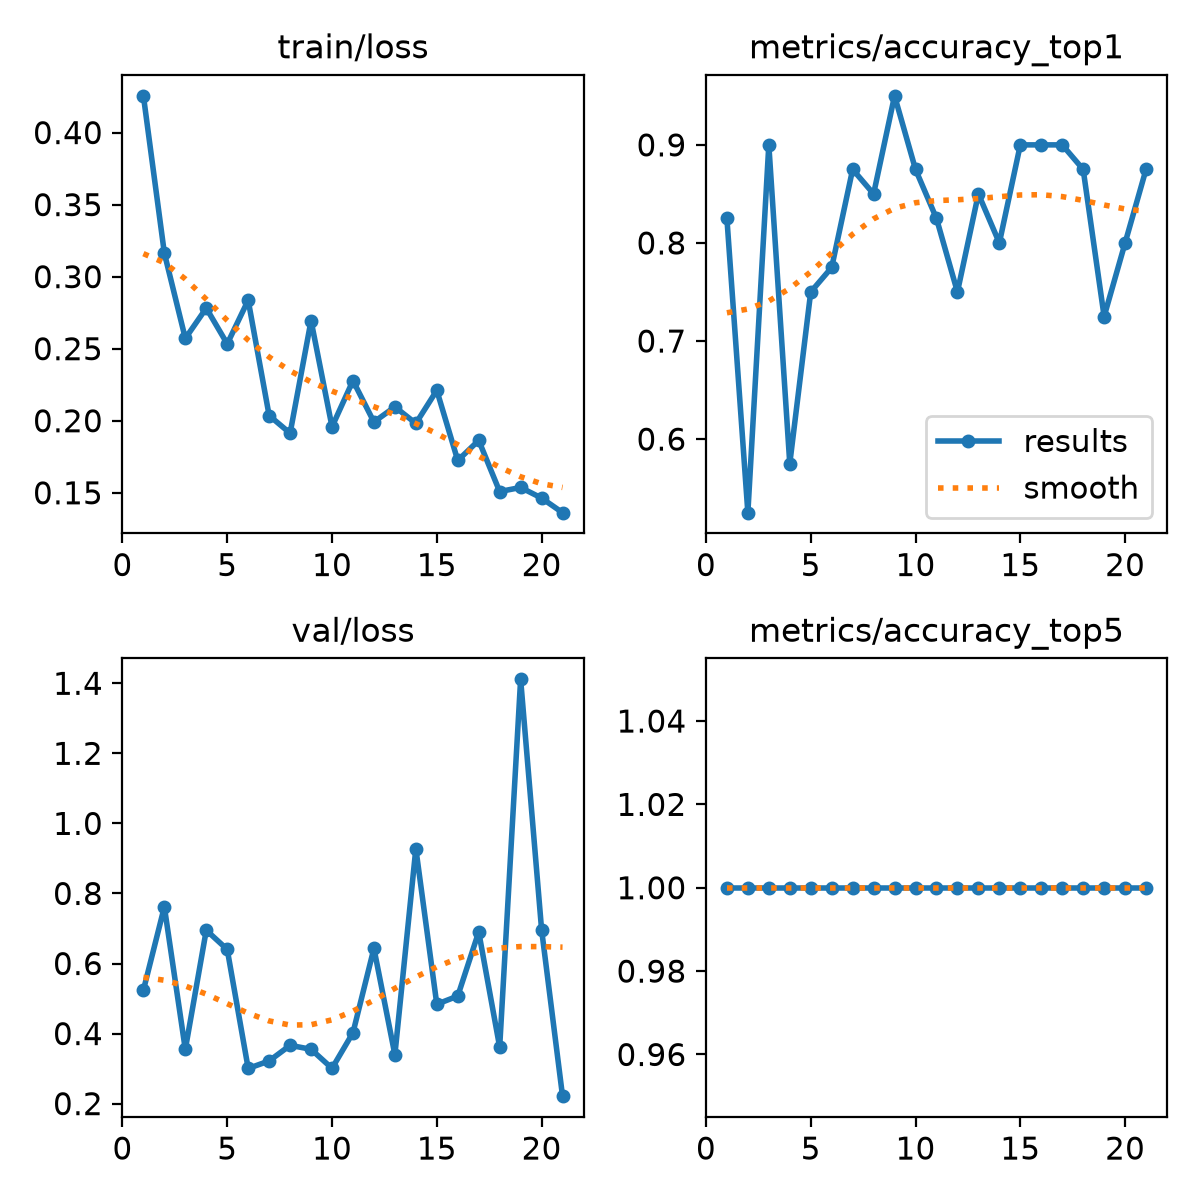

confusion_matrix.png


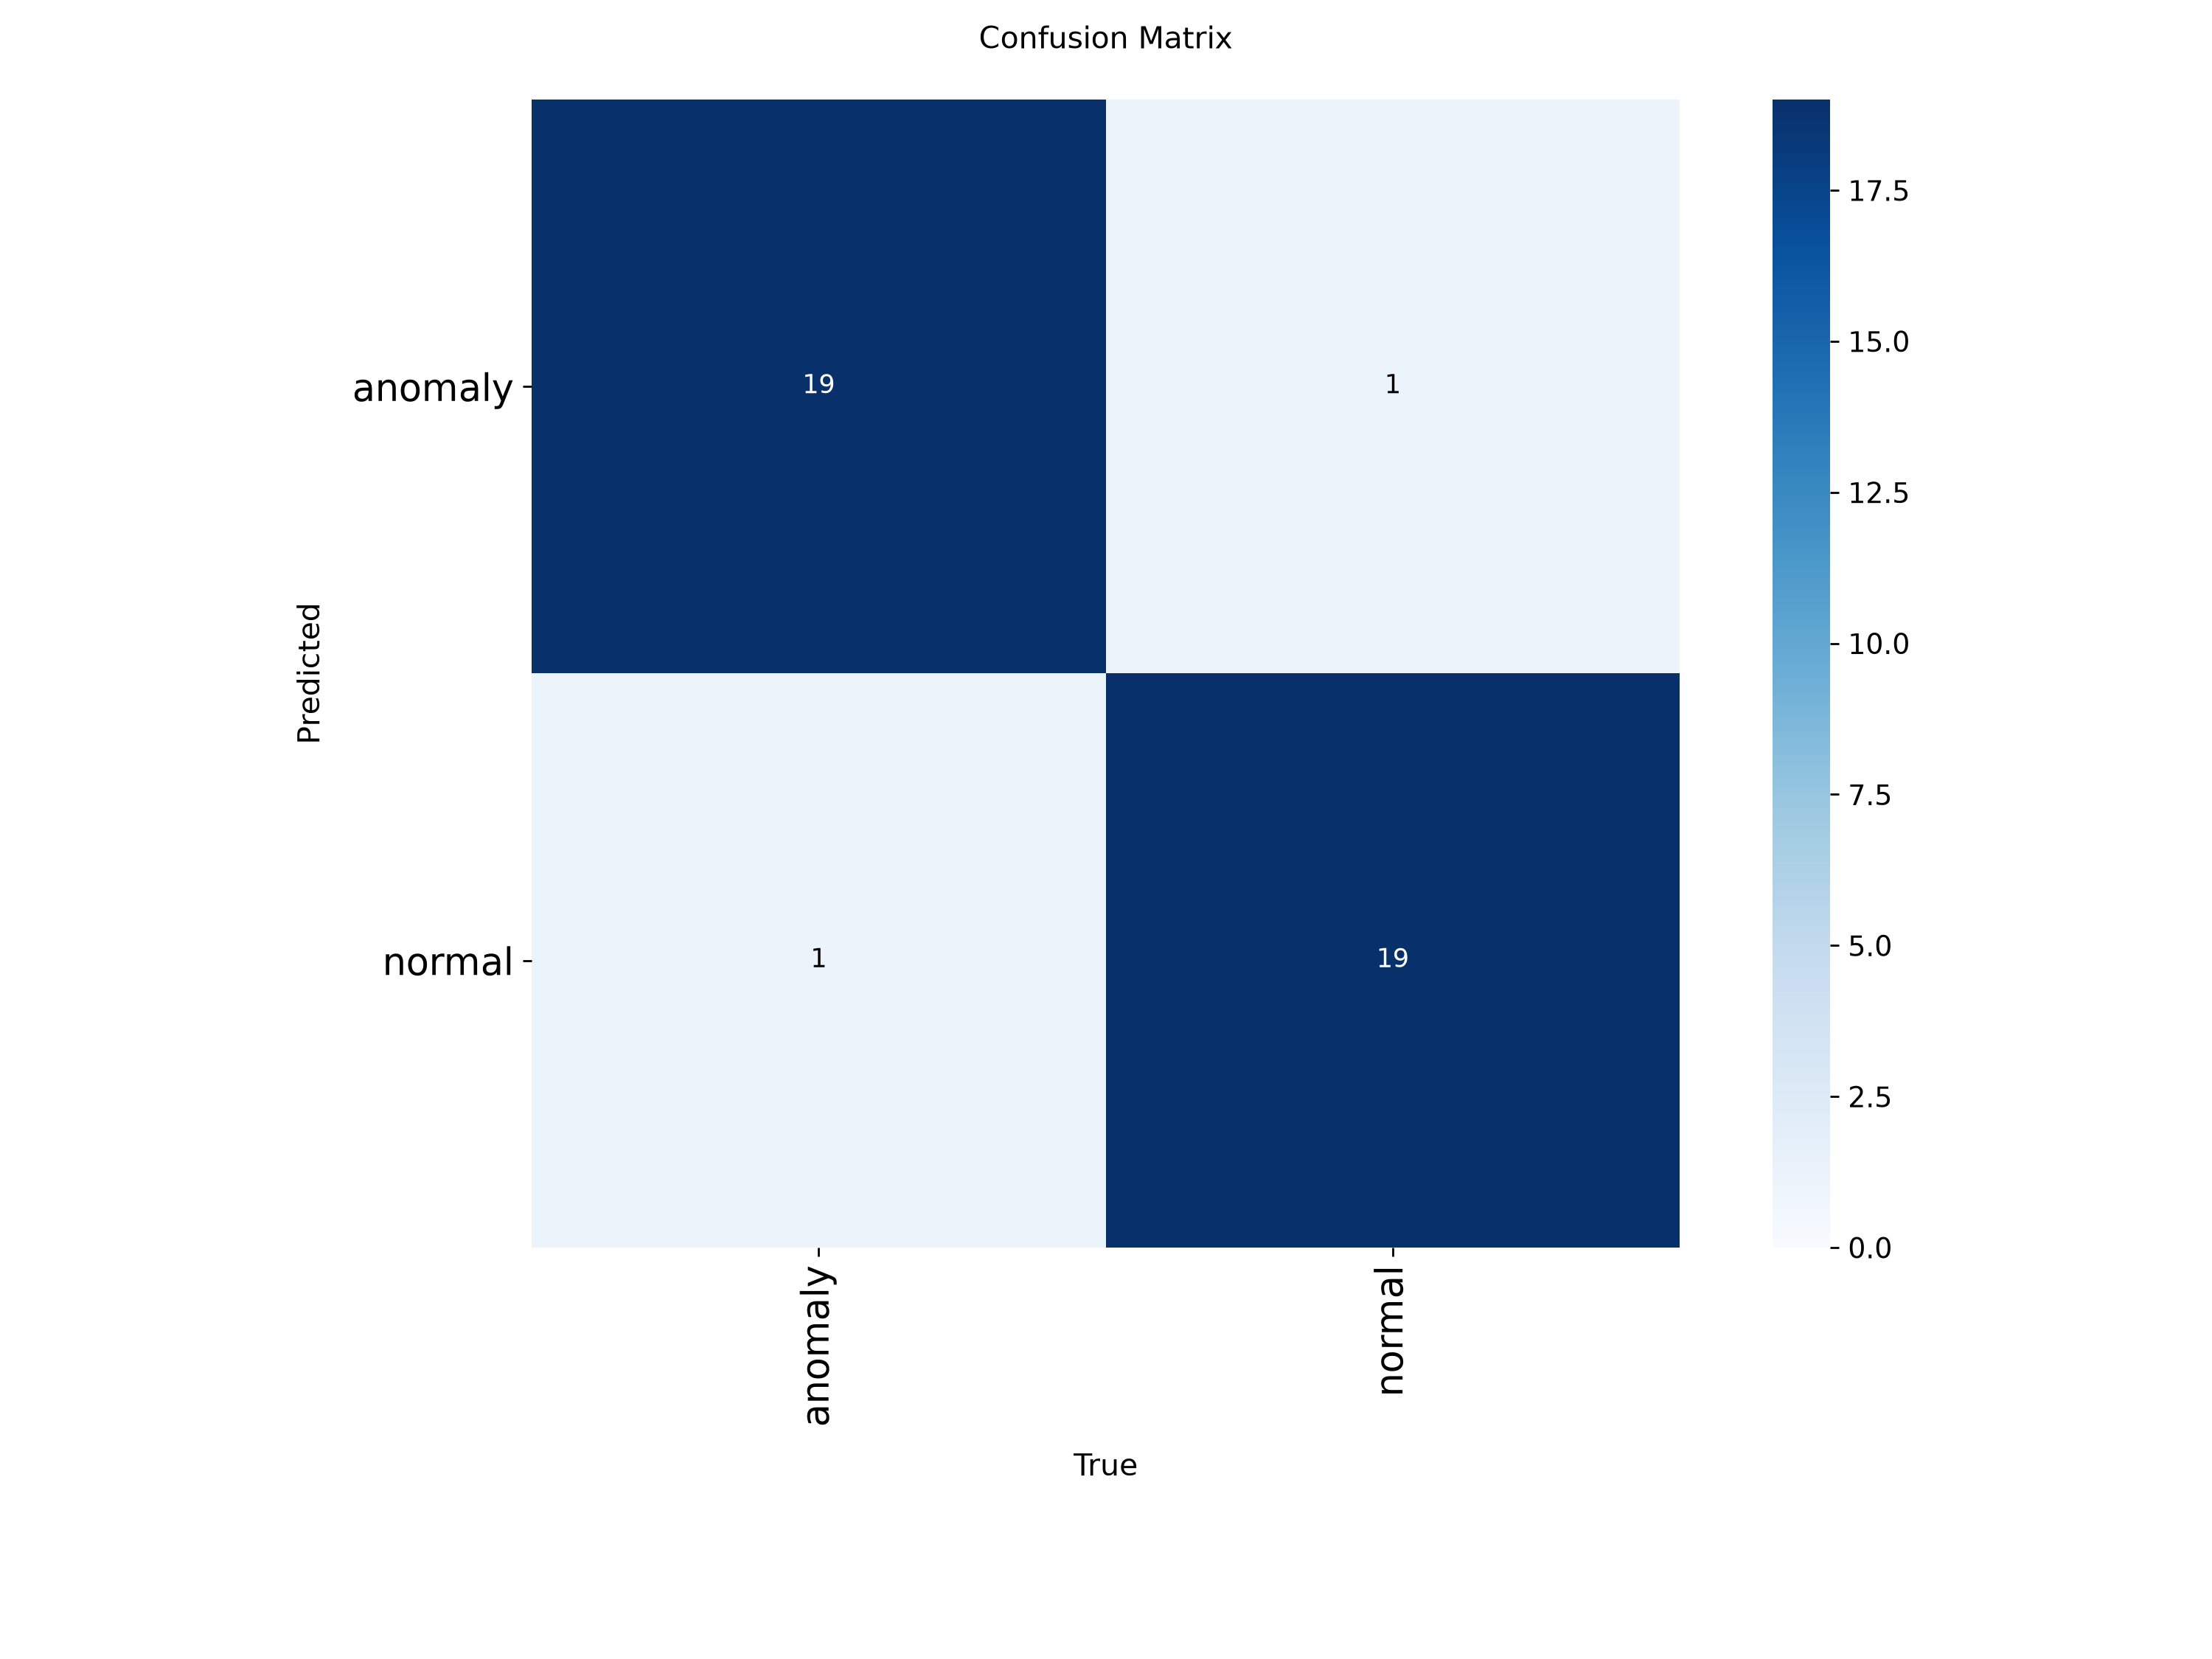

confusion_matrix_normalized.png


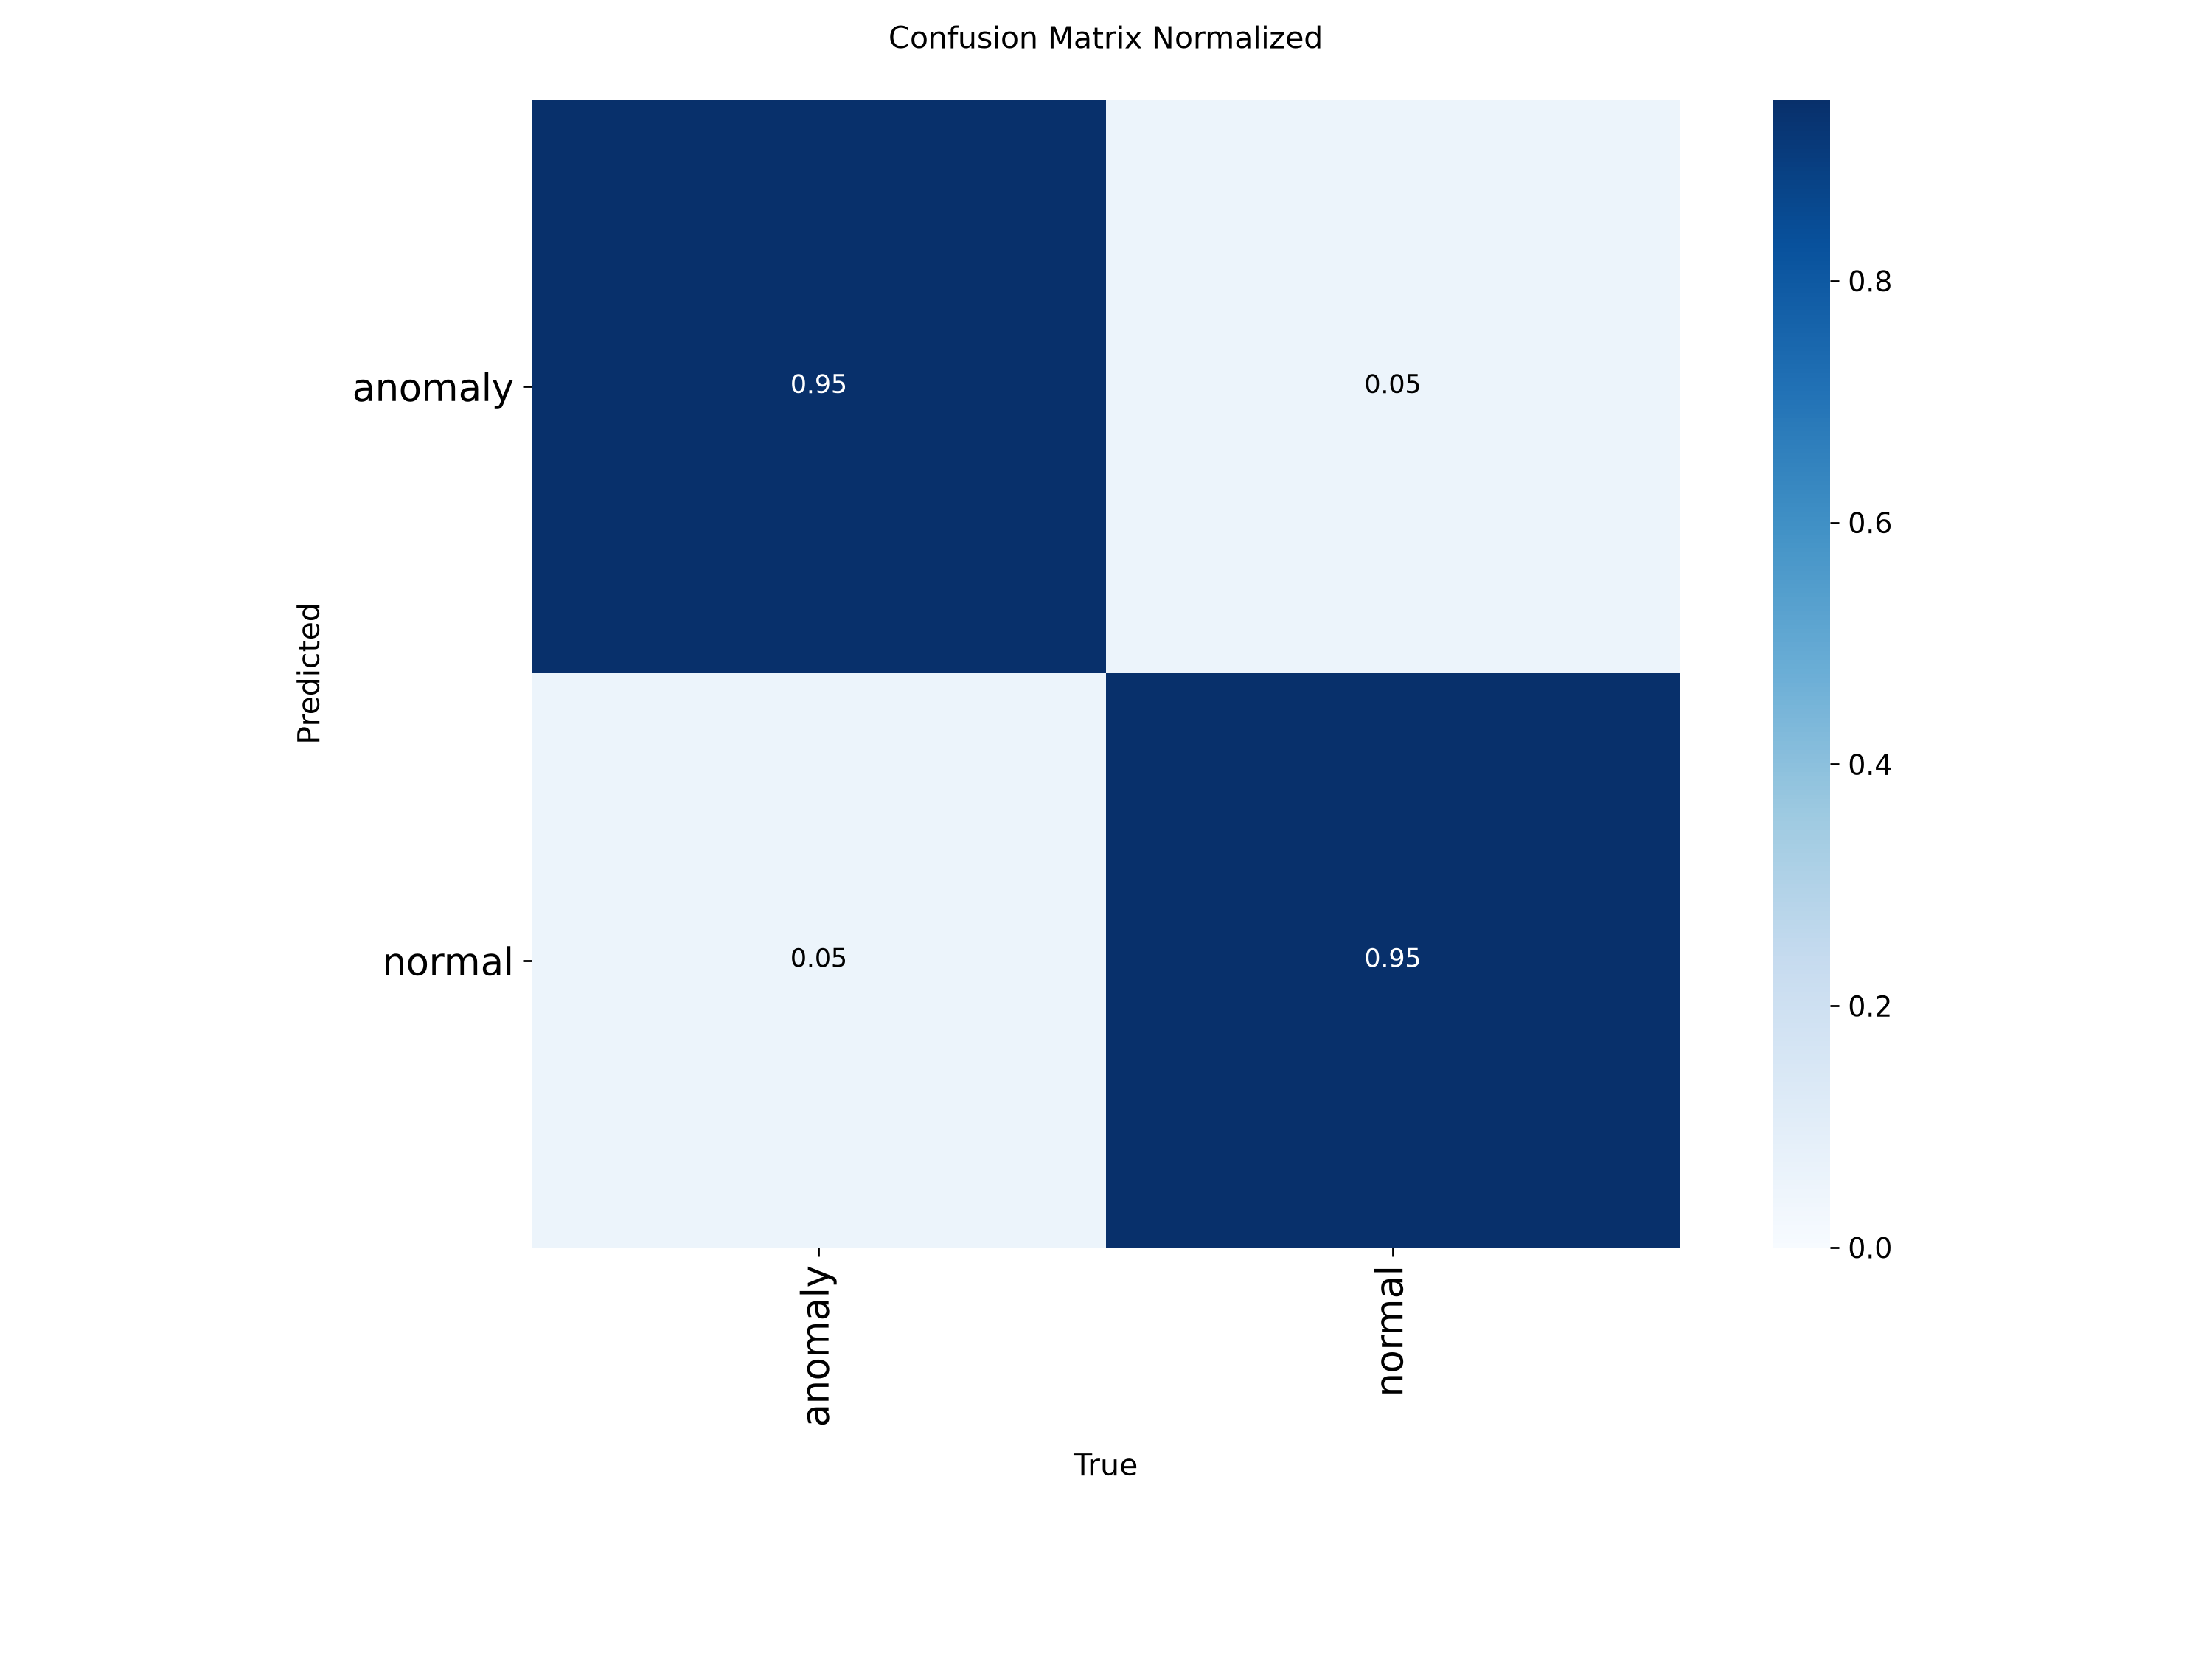

In [15]:
from IPython.display import Image as IPyImage, display as ipy_display

for png in ['results.png', 'confusion_matrix.png', 'confusion_matrix_normalized.png']:
    p = ROOT / 'results/yolo/pcb1_cls_v1' / png
    if p.is_file():
        print(png)
        ipy_display(IPyImage(filename=str(p), width=620))

---
## 7. Congelamiento del umbral en validación

Política común a ambos métodos: sobre la grilla `0.05 .. 0.95` paso `0.05`, se exige **FPR empírico máximo de 0,10**, y se maximiza **recall**, luego **F1**, luego se minimiza FPR. Empate total: primer umbral en orden ascendente.

- API: validación con 40 imágenes -> umbral **0,20** (FPR 0%, recall 95%).
- YOLO: validación recalculada hoy -> umbral **0,50**, congelado a las 11:20:52 (Lima), **antes** de ejecutar test (11:21:09).
- **Las probabilidades de test de YOLO no se usaron para elegir su umbral.**

Importante: esto es **selección de un punto operativo**, no calibración probabilística (no se hicieron isotonic/Platt ni diagramas de fiabilidad).

In [16]:
# Reproducimos la grilla y la politica sobre la validacion de YOLO guardada
yval = read_csv('results/audit_20261013/yolo_predictions_validation.csv')
yt = (yval['ground_truth'] == 'anomaly').values
yp = yval['probability'].values

grid = [i / 100 for i in range(5, 96, 5)]
cands = [metrics(yt, yp, t) for t in grid]
feasible = [c for c in cands if c['fpr'] <= 0.10]
chosen = max(feasible, key=lambda m: (m['recall'], m['f1'], -m['fpr']))

frozen = load_json('results/audit_20261013/yolo_threshold_frozen.json')
print('Umbral recalculado:', chosen['threshold'], '| umbral congelado:', frozen['selection']['threshold'])
print('Politica:', frozen['policy'])
print('delta maximo vs probabilidades historicas de validacion:', frozen['historical_val_max_probability_delta'])
assert chosen['threshold'] == frozen['selection']['threshold']
print('OK: la politica reproduce el umbral congelado.')

cand_df = pd.DataFrame([{'t': c['threshold'], 'accuracy': round(c['accuracy'], 4), 'recall': round(c['recall'], 4),
                         'F1': round(c['f1'], 4), 'FPR': round(c['fpr'], 4),
                         'TP/TN/FP/FN': abcd(c), 'factible': c['fpr'] <= 0.10} for c in cands])
display(cand_df)

Umbral recalculado: 0.5 | umbral congelado: 0.5
Politica: FPR <= 0.10; maximize recall, then F1, then minimize FPR; ascending grid first tie
delta maximo vs probabilidades historicas de validacion: 0.0
OK: la politica reproduce el umbral congelado.


,t,accuracy,recall,F1,FPR,TP/TN/FP/FN,factible
0,0.05,0.875,0.95,0.8837,0.20,19/16/4/1,False
1,0.10,0.875,0.95,0.8837,0.20,19/16/4/1,False
2,0.15,0.875,0.95,0.8837,0.20,19/16/4/1,False
3,0.20,0.875,0.95,0.8837,0.20,19/16/4/1,False
4,0.25,0.875,0.95,0.8837,0.20,19/16/4/1,False
5,0.30,0.900,0.95,0.9048,0.15,19/17/3/1,False
6,0.35,0.900,0.95,0.9048,0.15,19/17/3/1,False
7,0.40,0.900,0.95,0.9048,0.15,19/17/3/1,False
8,0.45,0.925,0.95,0.9268,0.10,19/18/2/1,True
9,0.50,0.950,0.95,0.9500,0.05,19/19/1/1,True


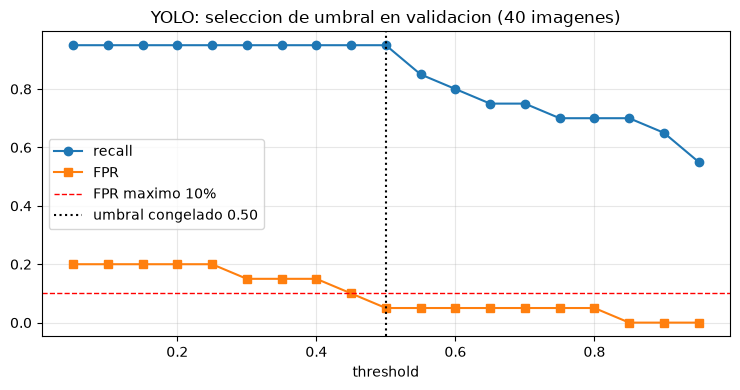

In [17]:
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(cand_df['t'], cand_df['recall'], marker='o', label='recall')
ax.plot(cand_df['t'], cand_df['FPR'], marker='s', label='FPR')
ax.axhline(0.10, ls='--', c='red', lw=1, label='FPR maximo 10%')
ax.axvline(chosen['threshold'], ls=':', c='black', label='umbral congelado %.2f' % chosen['threshold'])
ax.set_xlabel('threshold')
ax.set_title('YOLO: seleccion de umbral en validacion (40 imagenes)')
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

---
## 8. Comparación pareada en test

Ambos métodos se evalúan sobre **las mismas 60 imágenes**, con sus umbrales ya congelados. No hay nuevas llamadas a la API: se lee el test de YOLO inferido por la auditoría y el CSV del benchmark API.

In [18]:
ytest = read_csv('results/audit_20261013/yolo_predictions_test.csv')
api_test = test.set_index('image').loc[ytest['image'].values].reset_index()
assert (api_test['image'].values == ytest['image'].values).all()

y_true = (ytest['ground_truth'] == 'anomaly').values
y_prob = ytest['probability'].values.astype(float)
a_prob = api_test['probability'].values.astype(float)

T_YOLO, T_API = 0.50, 0.20
m_yolo = metrics(y_true, y_prob, T_YOLO)
m_api = metrics(y_true, a_prob, T_API)

display(pd.DataFrame([
    metrics_row('YOLO11n-cls', m_yolo),
    metrics_row('Decisions API V1', m_api),
]))

frozen_cmp = load_json('results/audit_20261013/comparison_test.json')
print('Coincide YOLO con comparison_test.json:', abs(frozen_cmp['yolo']['accuracy'] - m_yolo['accuracy']) < 1e-12)
print('Coincide API  con comparison_test.json:', abs(frozen_cmp['decisions_api']['accuracy'] - m_api['accuracy']) < 1e-12)
print('Mejora observada: accuracy +%.2f puntos | recall +%.2f puntos' % (
    100 * (m_yolo['accuracy'] - m_api['accuracy']), 100 * (m_yolo['recall'] - m_api['recall'])))

,metodo,N,t,accuracy,precision,recall,F1,FPR,TP/TN/FP/FN
0,YOLO11n-cls,60,0.5,93.33%,90.62%,96.67%,0.9355,10.00%,29/27/3/1
1,Decisions API V1,60,0.2,81.67%,85.19%,76.67%,0.8070,13.33%,23/26/4/7


Coincide YOLO con comparison_test.json: True
Coincide API  con comparison_test.json: True
Mejora observada: accuracy +11.67 puntos | recall +20.00 puntos


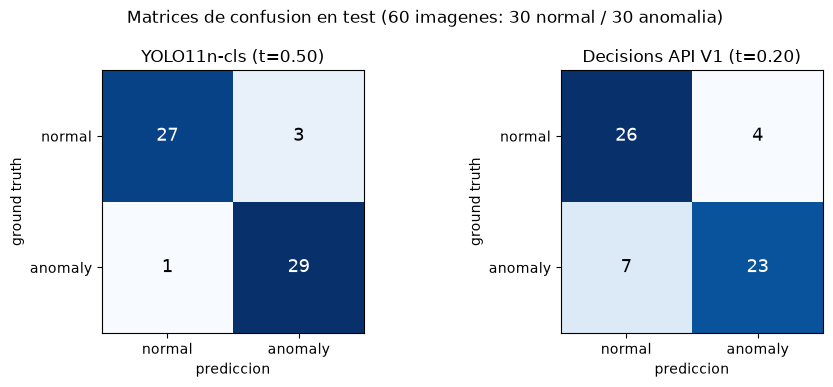

In [19]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.9))
for ax, name, prob, t in [(axes[0], 'YOLO11n-cls (t=0.50)', y_prob, T_YOLO),
                          (axes[1], 'Decisions API V1 (t=0.20)', a_prob, T_API)]:
    cm = confusion_matrix(y_true, prob >= t, labels=[False, True])
    ax.imshow(cm, cmap='Blues')
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, str(v), ha='center', va='center',
                color='black' if v < cm.max() / 2 else 'white', fontsize=13)
    ax.set_xticks([0, 1], ['normal', 'anomaly'])
    ax.set_yticks([0, 1], ['normal', 'anomaly'])
    ax.set_xlabel('prediccion')
    ax.set_ylabel('ground truth')
    ax.set_title(name)
plt.suptitle('Matrices de confusion en test (60 imagenes: 30 normal / 30 anomalia)')
plt.tight_layout()
plt.show()

In [20]:
from math import comb

pred_y = y_prob >= T_YOLO
pred_a = a_prob >= T_API
corr_y = pred_y == y_true
corr_a = pred_a == y_true
b = int(np.sum(corr_y & ~corr_a))
c = int(np.sum(corr_a & ~corr_y))
n = b + c
p_exact = min(1.0, 2 * sum(comb(n, i) for i in range(min(b, c) + 1)) / 2 ** n) if n else 1.0

print('Discordancias: YOLO acierta y API falla = %d | API acierta y YOLO falla = %d' % (b, c))
print('McNemar exacto bilateral p = %.7f' % p_exact)
print('Registrado en comparison_test.json: p =', frozen_cmp['paired_discordance']['mcnemar_exact_two_sided_p'])

display(pd.DataFrame([
    {'metodo': 'YOLO11n-cls', 'accuracy IC95%': ci_str(m_yolo['accuracy_ci95']),
     'recall IC95%': ci_str(m_yolo['recall_ci95']), 'FPR IC95%': ci_str(m_yolo['fpr_ci95'])},
    {'metodo': 'Decisions API V1', 'accuracy IC95%': ci_str(m_api['accuracy_ci95']),
     'recall IC95%': ci_str(m_api['recall_ci95']), 'FPR IC95%': ci_str(m_api['fpr_ci95'])},
]))
print('Interpretacion: analisis exploratorio; muestra pequena, un solo experimento, eleccion del sistema.')

Discordancias: YOLO acierta y API falla = 8 | API acierta y YOLO falla = 1
McNemar exacto bilateral p = 0.0390625
Registrado en comparison_test.json: p = 0.0390625


,metodo,accuracy IC95%,recall IC95%,FPR IC95%
0,YOLO11n-cls,84.07% - 97.38%,83.33% - 99.41%,3.46% - 25.62%
1,Decisions API V1,70.08% - 89.44%,59.07% - 88.21%,5.31% - 29.68%


Interpretacion: analisis exploratorio; muestra pequena, un solo experimento, eleccion del sistema.


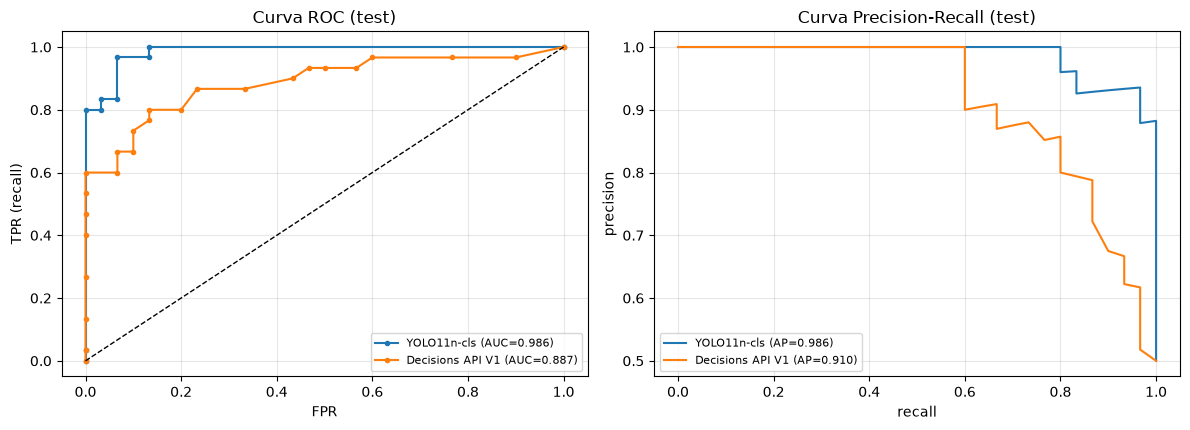

Prevalencia de test = 0.50 (1:1). El AUC/AP es exploratorio, no una estimacion poblacional.


In [21]:
# Curvas ROC y Precision-Recall sobre el test (exploratorio, con los umbrales congelados)
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, average_precision_score

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for name, prob, color in [('YOLO11n-cls', y_prob, 'tab:blue'), ('Decisions API V1', a_prob, 'tab:orange')]:
    fpr_c, tpr_c, _ = roc_curve(y_true, prob)
    axes[0].plot(fpr_c, tpr_c, marker='.', color=color,
                 label='%s (AUC=%.3f)' % (name, roc_auc_score(y_true, prob)))
    prec_c, rec_c, _ = precision_recall_curve(y_true, prob)
    axes[1].plot(rec_c, prec_c, color=color,
                 label='%s (AP=%.3f)' % (name, average_precision_score(y_true, prob)))

axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].set_xlabel('FPR')
axes[0].set_ylabel('TPR (recall)')
axes[0].set_title('Curva ROC (test)')
axes[1].set_xlabel('recall')
axes[1].set_ylabel('precision')
axes[1].set_title('Curva Precision-Recall (test)')
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print('Prevalencia de test = 0.50 (1:1). El AUC/AP es exploratorio, no una estimacion poblacional.')

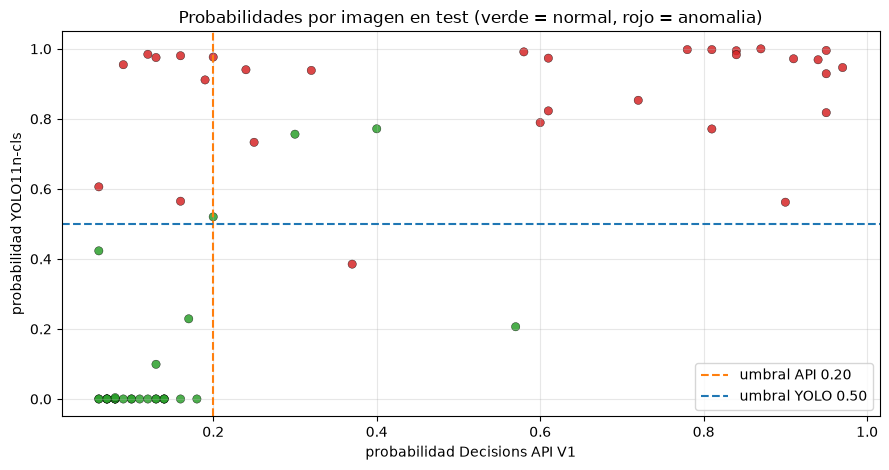

In [22]:
fig, ax = plt.subplots(figsize=(9, 4.8))
colors = np.where(y_true, 'tab:red', 'tab:green')
ax.scatter(a_prob, y_prob, c=colors, alpha=0.85, edgecolor='k', linewidth=0.3)
ax.axvline(T_API, ls='--', c='tab:orange', label='umbral API 0.20')
ax.axhline(T_YOLO, ls='--', c='tab:blue', label='umbral YOLO 0.50')
ax.set_xlabel('probabilidad Decisions API V1')
ax.set_ylabel('probabilidad YOLO11n-cls')
ax.set_title('Probabilidades por imagen en test (verde = normal, rojo = anomalia)')
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

---
## 9. Diagnóstico de errores con máscaras

- Se procesaron las **100 máscaras anómalas** de `pcb1` (10 exploración, 40 train, 20 validation, 30 test).
- Las máscaras contienen IDs `0-4`; positivo = `mask > 0`.
- Mapa oficial de clases: `1 Bent, 2 Melt, 3 Scratch, 4 Missing`.
- Las máscaras se usaron **después** de la evaluación y **solo para diagnóstico**: nunca como entrada a los modelos.
- En test, el área anómala mediana ocupa ~**0,22%** de la imagen.
- Proyectando con nearest a `Resize(320)+CenterCrop`, **0 de 30** anomalías pierden todos sus píxeles positivos, y todos los FN conservan el 100% (aproximado). Es una comprobación de que el recorte no borra la región anotada, **no** una explicación causal del error.

In [23]:
inv_err = read_csv('results/audit_20261013/error_inventory.csv')
test_err = inv_err[inv_err['experiment'].isin(['API_test_v1', 'YOLO_test'])].copy()
test_err['imagen'] = test_err['image'].str.split('/').str[-1]

display(test_err[['experiment', 'imagen', 'error', 'probability', 'threshold',
                  'annotation_labels', 'mask_area_fraction', 'approx_crop_retained_fraction']])
print('Conteo por metodo y tipo:', test_err.groupby(['experiment', 'error']).size().to_dict())
both = test_err.groupby(['imagen', 'error'])['experiment'].nunique()
print('Errores comunes (misma imagen y mismo tipo en ambos metodos):')
display(both[both > 1].reset_index())

,experiment,imagen,error,probability,threshold,annotation_labels,mask_area_fraction,approx_crop_retained_fraction
14,API_test_v1,044.JPG,FN,0.160000,0.2,missing,0.078977,1.0
15,API_test_v1,046.JPG,FN,0.190000,0.2,missing,0.063314,1.0
16,API_test_v1,048.JPG,FN,0.090000,0.2,missing,0.001086,1.0
17,API_test_v1,051.JPG,FN,0.130000,0.2,"melt,missing",0.002886,1.0
18,API_test_v1,054.JPG,FN,0.120000,0.2,missing,0.039441,1.0
19,API_test_v1,060.JPG,FN,0.060000,0.2,melt,0.000929,1.0
20,API_test_v1,062.JPG,FN,0.160000,0.2,melt,0.001243,1.0
21,API_test_v1,0684.JPG,FP,0.400000,0.2,normal,NaN,NaN
22,API_test_v1,0734.JPG,FP,0.570000,0.2,normal,NaN,NaN
23,API_test_v1,0776.JPG,FP,0.200000,0.2,normal,NaN,NaN


Conteo por metodo y tipo: {('API_test_v1', 'FN'): 7, ('API_test_v1', 'FP'): 4, ('YOLO_test', 'FN'): 1, ('YOLO_test', 'FP'): 3}
Errores comunes (misma imagen y mismo tipo en ambos metodos):


,imagen,error,experiment
0,0684.JPG,FP,2
1,0776.JPG,FP,2
2,0811.JPG,FP,2


In [27]:
ms = read_csv('results/audit_20261013/mask_statistics.csv')
summary = ms.groupby('split')['area_fraction'].agg(['count', 'min', 'median', 'max'])
summary['count'] = summary['count'].astype(int)
for col in ['min', 'median', 'max']:
    summary[col] = summary[col].map(lambda v: '%.4f%%' % (100 * v))
display(summary)

print('Retencion minima aproximada tras Resize(320)+CenterCrop, por split:',
      ms.groupby('split')['approx_retained_fraction'].min().round(4).to_dict())
print('Etiquetas de defecto presentes:', ms['annotation_labels'].str.split(',').explode().value_counts().to_dict())
print('IDs de pixel distintos encontrados:', sorted({int(i) for s in ms['pixel_ids'] for i in str(s).split(',')}))

,count,min,median,max
split,,,,
exploration,10,0.1202%,0.1914%,5.3247%
test,30,0.0929%,0.2166%,7.8977%
train,40,0.0766%,0.2094%,12.7259%
validation,20,0.0905%,0.1855%,7.8936%


Retencion minima aproximada tras Resize(320)+CenterCrop, por split: {'exploration': 1.0, 'test': 1.0, 'train': 1.0, 'validation': 1.0}
Etiquetas de defecto presentes: {'melt': 54, 'scratch': 21, 'missing': 20, 'bent': 15}
IDs de pixel distintos encontrados: [1, 2, 3, 4]


Figura: test_false_negative_masks.png | contornos = ground truth (no localizacion de los modelos)


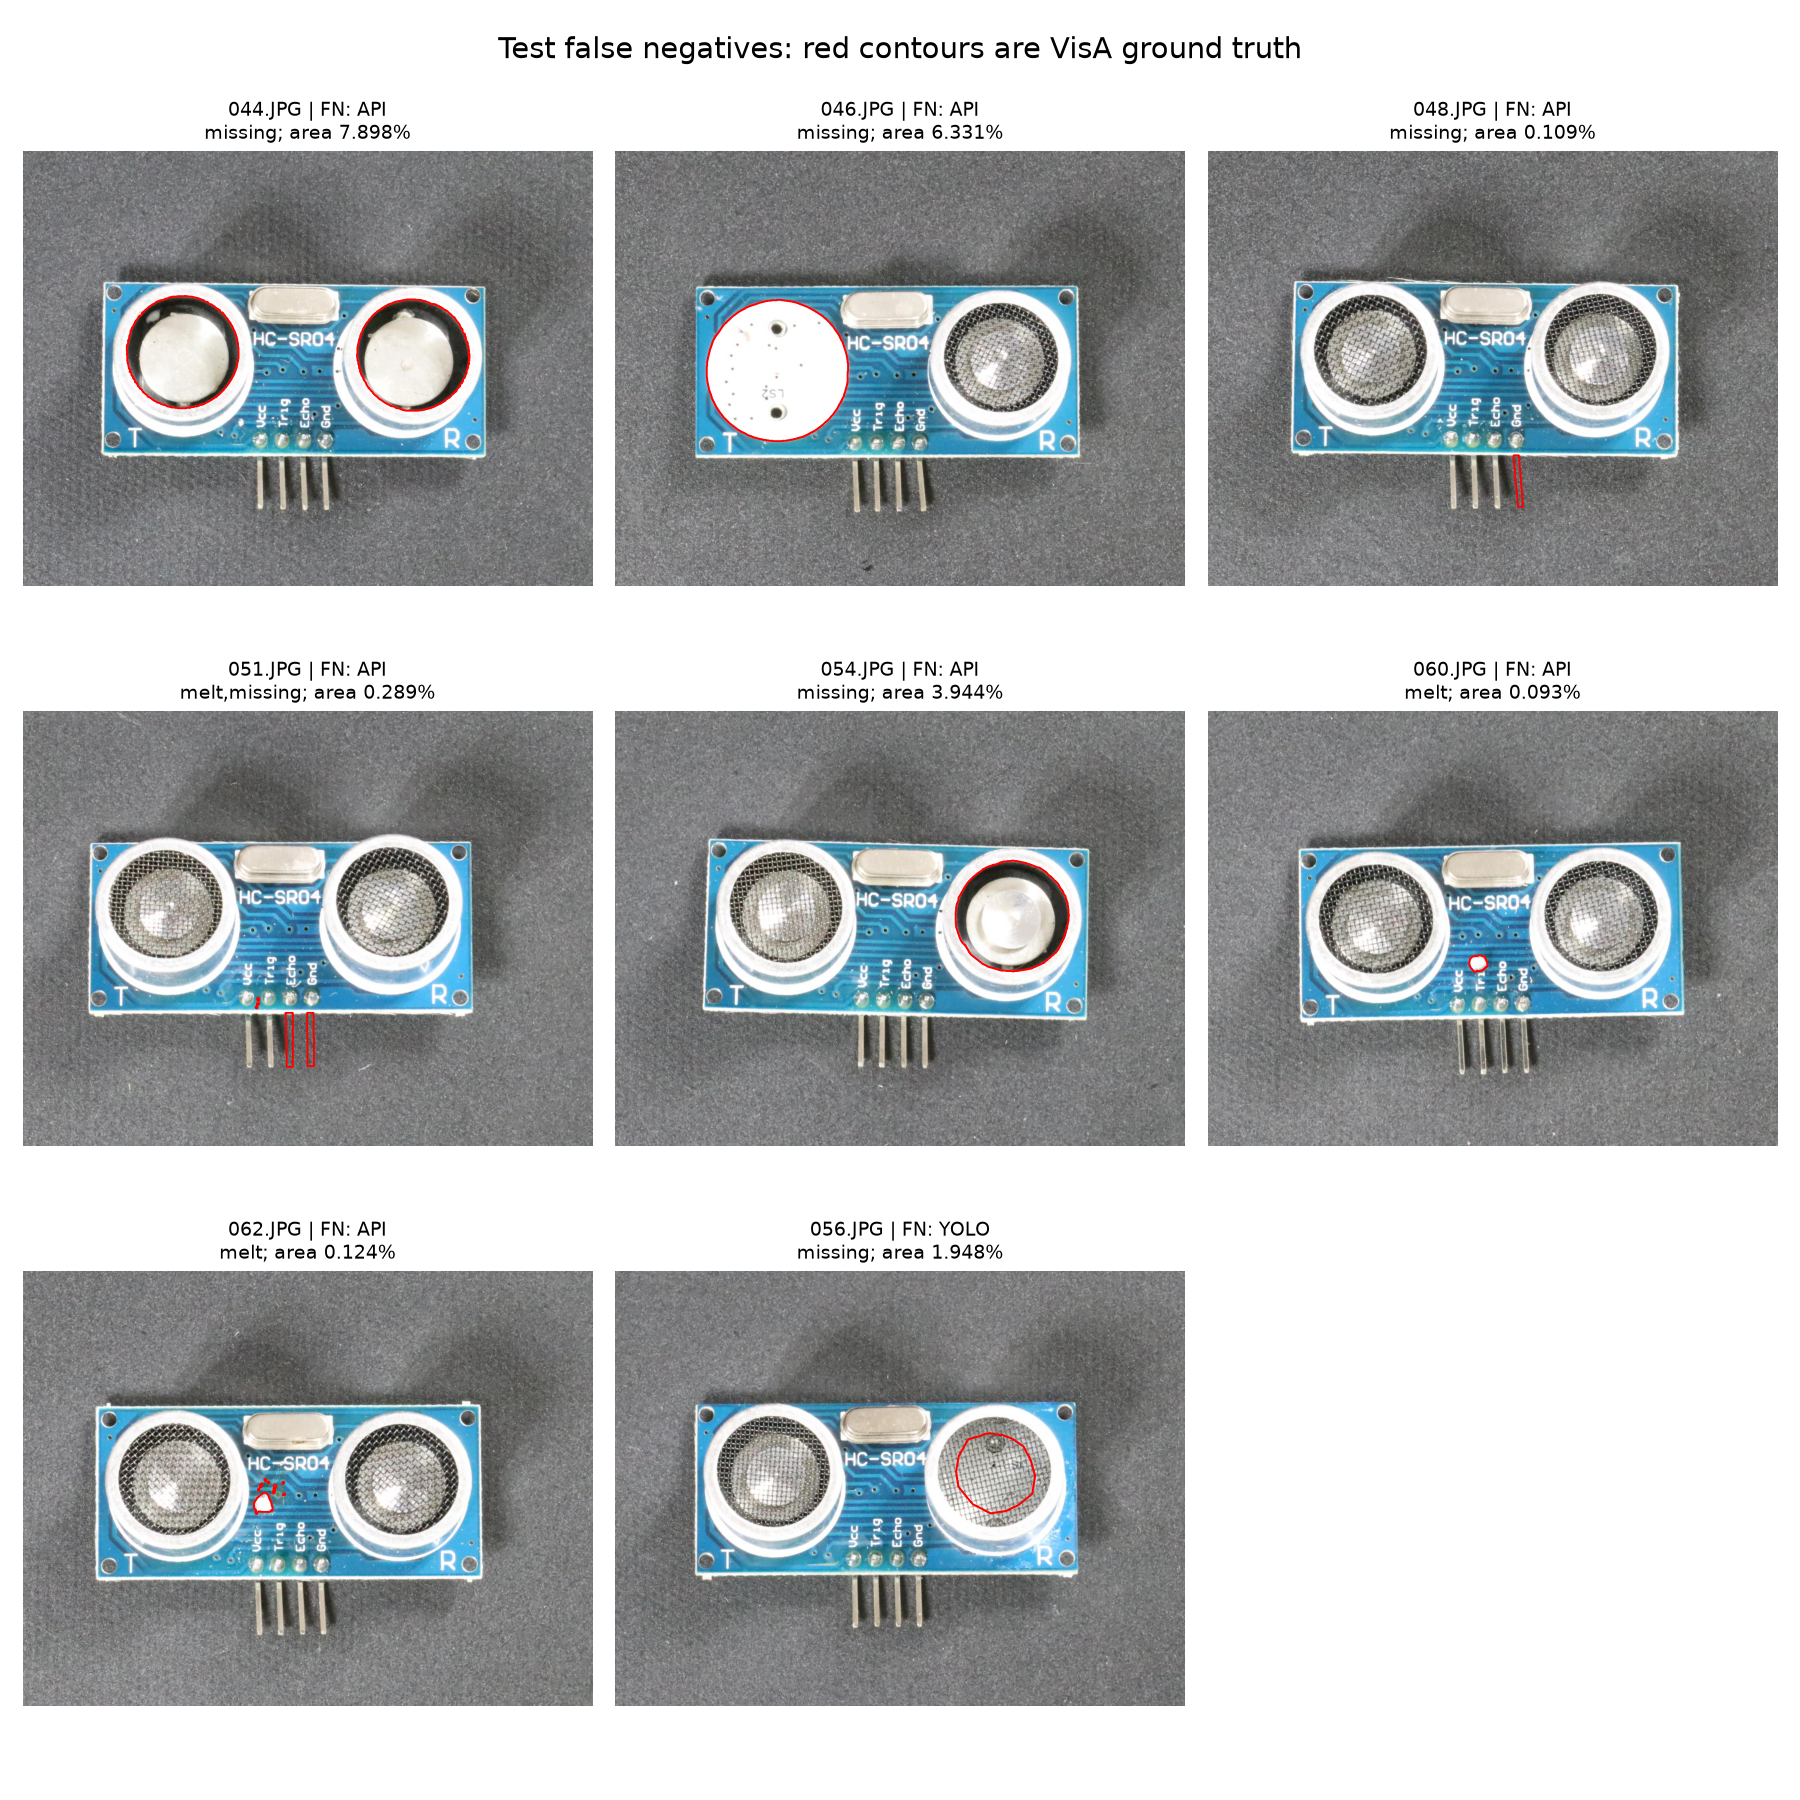

In [28]:
fig_path = AUDIT / 'test_false_negative_masks.png'
if fig_path.is_file():
    print('Figura:', fig_path.name, '| contornos = ground truth (no localizacion de los modelos)')
    ipy_display(IPyImage(filename=str(fig_path), width=900))
else:
    print('Figura no disponible:', fig_path)

---
## 10. Latencia y entorno

**Equipo:** RTX 5050 Laptop GPU, driver 610.74, 8.151 MiB, Python 3.11.9, PyTorch 2.11.0+cu128 (CUDA runtime 12.8), Ultralytics 8.4.177, SDK OpenAI 3.29.0.

**Advertencia de comparabilidad:** la latencia de la API incluye red, servicio y posibles reintentos; la de YOLO incluye arranque local, preprocesado e inferencia en GPU. **No son un benchmark homogéneo** y no se declara factor de aceleración. No hay coste monetario verificado.

{
  "python": "3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]",
  "torch": "2.11.0+cu128",
  "cuda_runtime": "12.8",
  "gpu": "NVIDIA GeForce RTX 5050 Laptop GPU",
  "ultralytics": "8.4.177"
}
Clases del modelo: {'0': 'anomaly', '1': 'normal'}
Transformaciones de inferencia:
Compose(
    Resize(size=320, interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(320, 320))
    ToTensor()
    Normalize(mean=tensor([0., 0., 0.]), std=tensor([1., 1., 1.]))
)
Entorno identico en la fase de test: True


,metodo,latencia_media_ms,nota
0,YOLO11n-cls,27.34,media con la primera llamada (arranque)
1,YOLO11n-cls,19.61,excluyendo la primera llamada
2,Decisions API V1,1062.13,historica: red/servicio/reintentos


Mediciones comparables: False


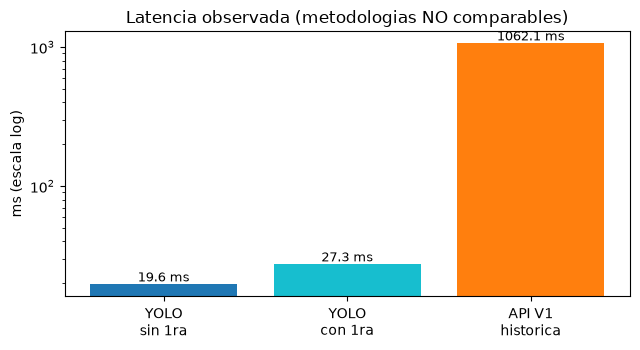

In [29]:
env = load_json('results/audit_20261013/environment.json')
env_test = load_json('results/audit_20261013/environment_test.json')
print(json.dumps({k: env[k] for k in ['python', 'torch', 'cuda_runtime', 'gpu', 'ultralytics']}, indent=2))
print('Clases del modelo:', env['names'])
print('Transformaciones de inferencia:')
print(env['transforms'])
print('Entorno identico en la fase de test:', env == env_test)

lat_info = frozen_cmp['latency']
display(pd.DataFrame([
    {'metodo': 'YOLO11n-cls', 'latencia_media_ms': round(lat_info['yolo_mean_ms'], 2), 'nota': 'media con la primera llamada (arranque)'},
    {'metodo': 'YOLO11n-cls', 'latencia_media_ms': round(lat_info['yolo_excluding_first_mean_ms'], 2), 'nota': 'excluyendo la primera llamada'},
    {'metodo': 'Decisions API V1', 'latencia_media_ms': round(lat_info['api_historical_mean_ms'], 2), 'nota': 'historica: red/servicio/reintentos'},
]))
print('Mediciones comparables:', lat_info['comparable'])

fig, ax = plt.subplots(figsize=(6.5, 3.6))
vals = [lat_info['yolo_excluding_first_mean_ms'], lat_info['yolo_mean_ms'], lat_info['api_historical_mean_ms']]
labs = ['YOLO\nsin 1ra', 'YOLO\ncon 1ra', 'API V1\nhistorica']
bars = ax.bar(labs, vals, color=['tab:blue', 'tab:cyan', 'tab:orange'])
ax.set_yscale('log')
ax.set_ylabel('ms (escala log)')
ax.set_title('Latencia observada (metodologias NO comparables)')
for bar, v in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width() / 2, v, '%.1f ms' % v, ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

---
## 11. Integridad y trazabilidad

La auditoría del 13-10-2026 se ejecutó con apertura **exclusiva** de archivos (se rechaza sobrescribir una etapa ya terminada) y verificó:

- Semilla 42 reproduce el manifiesto; 340 imágenes sin duplicados por ruta ni por contenido entre splits.
- Explicitud del solapamiento del smoke test inicial (no se ocultó la salvedad).
- 340 copias YOLO idénticas a los originales (SHA-256).
- Las métricas de validación/test de la API coinciden con sus checkpoints y con `final_test_metrics.json`.
- El umbral YOLO se congeló **antes** de inferir test; no se reutilizaron probabilidades de test para elegirlo.

Hashes clave:

- `best.pt` = `31b2b128e312217b5c253f2910f57788536c4557f40431a5fcf76cda8703178d`
- `data/pcb1_splits.csv` = `fce4468a8bafcf8915f8bf656cd2ba437d214af2d958697fa9e914859c6a19d2`

In [30]:
verification = load_json('results/audit_20261013/verification.json')
original_hashes = load_json('results/audit_20261013/original_hashes.json')

print('audit.checks_passed     :', audit['checks_passed'])
print('manifest_sha256 (audit) :', audit['manifest_sha256'])
print('model_sha256 (audit)    :', audit['model_sha256'])
print('sha256 best.pt real     :', sha256('results/yolo/pcb1_cls_v1/weights/best.pt'))
print('sha256 manifest real    :', sha256('data/pcb1_splits.csv'))
print('hashes originales registrados:', len(original_hashes))
print()
print('Nuevas llamadas API en la continuacion :', verification['new_api_calls'])
print('Nuevos entrenamientos                  :', verification['new_training_runs'])
print('Archivos originales verificados        :', verification['original_files_verified'])
print('Archivos originales modificados        :', verification['original_files_modified'])
display(pd.DataFrame({'verificaciones': verification['checks']}))

audit.checks_passed     : True
manifest_sha256 (audit) : fce4468a8bafcf8915f8bf656cd2ba437d214af2d958697fa9e914859c6a19d2
model_sha256 (audit)    : 31b2b128e312217b5c253f2910f57788536c4557f40431a5fcf76cda8703178d
sha256 best.pt real     : 31b2b128e312217b5c253f2910f57788536c4557f40431a5fcf76cda8703178d
sha256 manifest real    : fce4468a8bafcf8915f8bf656cd2ba437d214af2d958697fa9e914859c6a19d2
hashes originales registrados: 179

Nuevas llamadas API en la continuacion : 0
Nuevos entrenamientos                  : 0
Archivos originales verificados        : 179
Archivos originales modificados        : 0


,verificaciones
0,validation: metrics independently match sklearn
1,test: metrics independently match sklearn
2,"threshold boundary is >=, including exactly 0.20"
3,duplicate test predictions rejected
4,audit: repeated execution rejected before infe...
5,freeze: repeated execution rejected before inf...
6,test: repeated execution rejected before infer...
7,frozen threshold obeys validation policy and a...
8,all original artifact hashes unchanged
9,all documentation local links resolve


---
## 12. Limitaciones (lo que estos números NO dicen)

1. **Solo `pcb1`**, test de 60 imágenes (30/30). Los intervalos son amplios y no representan una línea con otra prevalencia.
2. **Train 5:1 desbalanceado** y solo 40 anomalías de entrenamiento. Partición local, no protocolo oficial. No se verificó separación por lote, pieza física o captura, ni duplicados perceptuales.
3. **Validation se usó dos veces**: para elegir `best.pt` y para elegir umbral. Su rendimiento está condicionado por esa selección; no es una estimación final independiente.
4. **El test de la API ya se inspeccionó** antes de esta continuación; YOLO no se ajustó con él. El conjunto debe retirarse de cualquier selección futura.
5. **YOLO recibió entrenamiento específico; la API no.** La comparación es entre esos sistemas finales con ese presupuesto de datos, no en igualdad de condiciones.
6. **V2 describe HC-SR04**, coherente con los casos inspeccionados; sus 6 FP exploratorios no demuestran desajuste de dominio ni que todo prompt detallado sea peor.
7. **Probabilidad no es calibración comprobada.** El umbral es operativo; un FPR máximo del 10% en validación no garantiza ese FPR en una población futura.
8. **Recorte central y 320 px de resolución** pueden perder o reducir anomalías; las estadísticas de máscaras proyectadas son aproximadas (nearest) y no prueban la causa de cada error.
9. **Las latencias no son comparables** (red vs GPU local) y no hay coste monetario verificado.
10. **La independencia comprobada es por rutas y bytes conocidos**: no garantiza ausencia de exposición en el preentrenamiento del proveedor de la API.

---
## 13. Próximos pasos (planes, sin resultados atribuidos)

1. Revisión **manual caso por caso** de FP/FN y máscaras, con criterio de anotación consistente.
2. Nueva separación por **lote/captura** para categorías adicionales, excluyendo imágenes ya vistas; reservar un **test nuevo** antes de cambiar el sistema.
3. Comparar imagen completa vs **tiles/recortes** vs mayor resolución en validación nueva; congelar arquitectura y umbral antes de abrir el test.
4. Evaluar **más semillas** y learning curves sobre anomalías supervisadas; medir la variabilidad del entrenamiento.
5. Proponer un **prompt V3** con contexto correcto de `pcb1` y hashes completos del experimento; revisar caché y coste antes de autorizar llamadas.
6. Medir **calibración probabilística** (isotonic/Platt, curvas de fiabilidad) y elegir costes FP/FN según la operación real.
7. Medir latencia warm/cold, throughput y coste con protocolo comparable; validar deriva y prevalencia real antes de cualquier integración operativa.

---
## 14. Reproducción

Para **leer** los resultados actuales solo hay que ejecutar este notebook. Los comandos siguientes sirven para una reproducción local nueva (escriben en un directorio que no exista):

```text
python scripts/offline_audit_compare.py audit  --output results/reproduccion_nueva
python scripts/offline_audit_compare.py freeze --output results/reproduccion_nueva
python scripts/offline_audit_compare.py test   --output results/reproduccion_nueva
```

- `audit` verifica conteos, exclusiones, semilla 42, hashes y las 340 copias YOLO.
- `freeze` infiere **solo validación**, comprueba coincidencia con el CSV histórico y congela el umbral.
- `test` exige el congelamiento previo y compara las mismas 60 imágenes.

**No ejecutar** `run_benchmark*.py` (llamadas pagadas), `train_yolo.py` (nuevo entrenamiento) ni los `prepare_*` (reescriben manifiestos) solo para actualizar documentación. El test ya fue visto: repetir inferencia verifica reproducibilidad, no crea una evaluación nueva.

In [31]:
cmds = [
    'python scripts/offline_audit_compare.py audit  --output results/reproduccion_nueva',
    'python scripts/offline_audit_compare.py freeze --output results/reproduccion_nueva',
    'python scripts/offline_audit_compare.py test   --output results/reproduccion_nueva',
]
for c in cmds:
    print('PS>', c)
print()
print('Documentacion de referencia:')
for doc in ['README.md', 'README-comparacion.md', 'reports/comparacion-20261013.md']:
    print(' -', doc, '| existe:', (ROOT / doc).is_file())

PS> python scripts/offline_audit_compare.py audit  --output results/reproduccion_nueva
PS> python scripts/offline_audit_compare.py freeze --output results/reproduccion_nueva
PS> python scripts/offline_audit_compare.py test   --output results/reproduccion_nueva

Documentacion de referencia:
 - README.md | existe: True
 - README-comparacion.md | existe: True
 - reports/comparacion-20261013.md | existe: True


---
## 15. Conclusiones

1. Sobre esta muestra local de 60 imágenes de `pcb1`, **YOLO11n-cls (entrenado con 240 imágenes) supera a Decisions API V1 sin ajuste específico**: 93,33% vs 81,67% de accuracy, y 96,67% vs 76,67% de recall.
2. La diferencia es estadísticamente sugestiva en McNemar (p = 0,0391) pero **exploratoria**: un solo experimento, muestra pequeña y elección del sistema.
3. Los dos métodos cometen errores **distintos**: no hay un solo FN común en test, y 3 FP sobre normales (0684, 0776, 0811) sí son comunes. Eso sugiere complementariedad, no redundancia.
4. La mayoría de los FN de la API corresponden a defectos tipo `missing` y `melt` de área muy pequeña (mediana ~0,22% de la imagen), coherente con la dificultad de detectar defectos sutiles sin entrenamiento específico.
5. El coste de YOLO es un entrenamiento etiquetado y dependencia de GPU; el de la API es latencia de red y coste por llamada. La decisión industrial depende de prevalencia real, coste de FP/FN y disponibilidad de datos etiquetados, ninguno evaluado aquí.
6. **Ningún resultado autoriza uso productivo.** Antes de eso: test nuevo, revisión manual, calibración probabilística, costes reales y validación de deriva.